# Same-initialization student distillation — results

Live analysis of `outputs/students/`, scoped by default to the July 2026 **same-initialization** treatment for **`dog`** on the original **`pythia-160m`** base: teacher and student share the `pythia-160m` checkpoint, the numbers are `ex10-20_prefix` (100k candidate pool, 10 000 trained rows), and both fine-tuning seeds are 1. Section 5 steps aside to the `cat` runs — the only base with a matched PolyPythia re-run — to isolate a base-model effect. Section 6 holds the teacher and student fixed and varies only the **number-generation mode** (free-gen baseline vs. the spliced-prompt and constrained-decoding variants).

The notebook visualizes run coverage, held-out transfer versus trained controls, student-epoch dose response, seed-matched teacher→student association, teacher hyperparameters, specificity/OOD behavior, the top configurations, a base-model comparison, and the number-generation-mode comparison.

> **Uncertainty warning.** Current treatment summaries contain one student seed. Persisted across-seed CIs therefore collapse to the point estimate. Spread across teacher configurations below is descriptive, not repeated-seed uncertainty.

> **Student-eval coverage.** The `dog` `pythia-160m` students were scored on `test` and `storytelling` only — the `off_topic`, `validation`, and `dislike` student prompt sets were not run for this base. Panels that depend on those sets (the specificity/off-topic view) therefore render empty; the teacher-side association still works because the teacher's own `validation` score is read directly. Backfill the student evals to repopulate them.

## Setup and artifact loader

Run from the repo root with `uv run --group analysis jupyter lab`. The loader joins every student to its training manifest and to the exact teacher seed that generated its number dataset.

In [1]:
from __future__ import annotations
import json, re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import spearmanr
from subliminal_learning.analysis import plots as aplots, student_tree
from subliminal_learning.analysis.setup import bootstrap, set_plot_style

ROOT, OUTPUT_ROOT = bootstrap()
STUDENTS_ROOT = OUTPUT_ROOT / "students"
# Sections 1-4 scope: dog on the original pythia-160m base, teacher/ft seed 1. (Section 5 reaches into cat directly.)
SAME_INIT_ANIMAL, SAME_INIT_MODEL, TEACHER_SEED, STUDENT_SEED = "dog", "pythia-160m", 1, 1
# Student recipe must be pinned too: the dose series (ep1..ep20) is only a *dose* series if the student
# LoRA/LR is held fixed. Later student-HP sweeps added 3 extra ep20 recipes into this same tree
# (ep20_lr3e-4_r16a8, ep20_lr4e-4_r16a4, ep20_lr4e-4_r32a4), which otherwise stack 4 runs per heatmap cell.
STUDENT_LR, STUDENT_RANK, STUDENT_ALPHA = 1e-4, 8, 32
# Dataset dirs carry a candidate-pool suffix (_n40k / _n100k); both train 10 000 rows. dog uses the 100k prefix pool.
LABEL = {"ex10-20_prefix_n100k":"prefix (100k pool)", "ex10-20_prefix_n40k":"prefix (40k pool)",
         "ex10-20_full10":"full10", "ex10-20_full10_3digit":"full10, 3-digit",
         # Number-generation modes compared in Section 6 (see there for the DGP caveat on the constrained pool).
         "ex10-20_prefix_n100k_spliced":"prefix, spliced prompts", "intro-u10_prefix_n10k":"constrained intro ≤10"}
COLOR = {"ex10-20_prefix_n100k":"#4c78a8", "ex10-20_prefix_n40k":"#4c78a8",
         "ex10-20_full10":"#f58518", "ex10-20_full10_3digit":"#54a24b",
         "ex10-20_prefix_n100k_spliced":"#b279a2", "intro-u10_prefix_n10k":"#9d755d"}
set_plot_style(dpi=115, grid_alpha=0.25, hide_spines=True)
print("output_root:", OUTPUT_ROOT)

output_root: /mnt/cold-1/soar-subliminal/angela/outputs


In [2]:
# The student-tree scan (treatment + control leaves, teacher-eval attachment) lives in
# `analysis.student_tree`; this notebook selects the columns it uses from the shared superset.
treatments_all, n_missing_manifest, n_skipped = student_tree.load_treatments(OUTPUT_ROOT)
controls_all = student_tree.load_controls(OUTPUT_ROOT)
# Sections 1-4: dog + original pythia-160m, same-init, teacher/ft seed 1.
same = treatments_all[treatments_all.same_init.eq(True) & treatments_all.animal.eq(SAME_INIT_ANIMAL) & treatments_all.model.eq(SAME_INIT_MODEL) &
                      treatments_all.teacher_seed.eq(TEACHER_SEED) & treatments_all.student_seeds.map(lambda seeds: seeds == (STUDENT_SEED,)) &
                      treatments_all.student_lr.eq(STUDENT_LR) & treatments_all.student_rank.eq(STUDENT_RANK) &
                      treatments_all.student_alpha.eq(STUDENT_ALPHA)].copy()
controls = (controls_all[controls_all.animal.eq(SAME_INIT_ANIMAL) & controls_all.model.eq(SAME_INIT_MODEL) &
                         controls_all.student_seeds.map(lambda seeds: seeds == (STUDENT_SEED,))].copy()
            if len(controls_all) else controls_all)
assert len(same), "selected same-initialization slice is empty"

META = ["config_id","animal","model","teacher_tag","teacher_seed","dataset","student_tag","teacher_epochs","teacher_lr",
        "teacher_rank","teacher_alpha","teacher_sig_validation","teacher_sig_test","student_epochs","student_lr",
        "student_rank","student_alpha","n_train","loss","steps"]
wide = same.drop_duplicates("config_id")[META].set_index("config_id")
for value, prefix in [("p","student_"),("teacher_p","teacher_"),("base_p","untuned_"),("rank","rank_")]:
    wide = wide.join(same.pivot(index="config_id", columns="set", values=value).add_prefix(prefix))
wide = wide.reset_index()
wide["teacher_lora"] = wide.apply(lambda x:f"r{x.teacher_rank}/α{x.teacher_alpha}", axis=1)
wide["lineage"] = wide.apply(lambda x:f"{x.teacher_tag}|t{x.teacher_seed}|{x.dataset}", axis=1)
# Optional student prompt sets. The original pythia-160m students carry only `test` and `storytelling`; ensure the
# richer per-set columns exist (as NaN) so panels degrade to empty instead of raising on a missing column.
for _pref in ("student_", "teacher_", "untuned_", "rank_"):
    for _set in ("test", "off_topic", "validation", "storytelling"):
        _col = f"{_pref}{_set}"
        if _col not in wide.columns: wide[_col] = np.nan
wide["test_minus_offtopic"] = wide.student_test - wide.student_off_topic
# Teacher signal: prefer the teacher's own `test`, else its `validation`, whichever the teacher eval actually scored.
TEACHER_SIGNAL_SET = "test" if wide.teacher_sig_test.notna().any() else "validation"
wide["teacher_signal"] = wide[f"teacher_sig_{TEACHER_SIGNAL_SET}"]

if len(controls):
    cm = controls.drop_duplicates("config_id")[["config_id","source","model","dataset","student_tag","student_epochs"]].set_index("config_id")
    controls_wide = cm.join(controls.pivot(index="config_id", columns="set", values="p").add_prefix("student_")).reset_index()
else: controls_wide = pd.DataFrame()
if n_missing_manifest: print(f"{n_missing_manifest} runs missing train_manifest.json — excluded")
if n_skipped: print(f"{n_skipped} dirs skipped by layout/regex filters")
print(f"{len(wide)} same-init configs ({SAME_INIT_ANIMAL} / {SAME_INIT_MODEL}); {wide.lineage.nunique()} teacher/dataset lineages; {len(controls_wide)} controls")
print("sets:", sorted(same["set"].unique()))

40 runs missing train_manifest.json — excluded
765 dirs skipped by layout/regex filters
1009 same-init configs (dog / pythia-160m); 228 teacher/dataset lineages; 17 controls
sets: ['storytelling', 'test']


## 1. Inventory and held-out transfer

A config is one `(teacher HP × number mode × student epoch)` result. `test` is the main held-out preference metric. Control markers are trained `base`/`rng` students, now backfilled at every student dose and plotted at their own epoch; the matched-Δ table below compares each number mode's treatment against the **dose-matched** (1-epoch) control.

The transfer chart is shown in **two rows**:

- **Row 1 — all collected configs.** Every completed config, one box per number mode × student dose.
- **Row 2 — shared cells (apples-to-apples).** The three number-generation modes — `prefix`, `prefix-spliced`, and `constrained-intro` — restricted to the teacher-HP cells present in **all three** modes, so every box aggregates over an identical config set.

A config can only train a same-init student if its teacher produced **≥ 10k usable number sequences**. Constrained decoding (`intro-u10`) guarantees valid output (keep-rate 1.0), so it yields a full pool for every teacher; free-gen (`ex10-20 prefix`) keep-rates vary and many degenerate (high-LR) teachers fall below 10k. Constrained students were trained on only a pre-selected subset of teachers (those correlated with stronger transfer), all of which also have free-gen students — so row 1's constrained box is drawn from that biased subset. Row 2's shared-cell restriction is what makes the mode comparison statistically fair.

student_epochs,1,2,5,10,20
prefix (100k pool),102,102,102,102,102
"prefix, spliced prompts",102,102,102,102,1
constrained intro ≤10,22,22,22,22,0


missing teacher scores by set:


set
test    1007
Name: missing, dtype: int64

teacher association signal: validation
training rows: [np.int64(10000)]


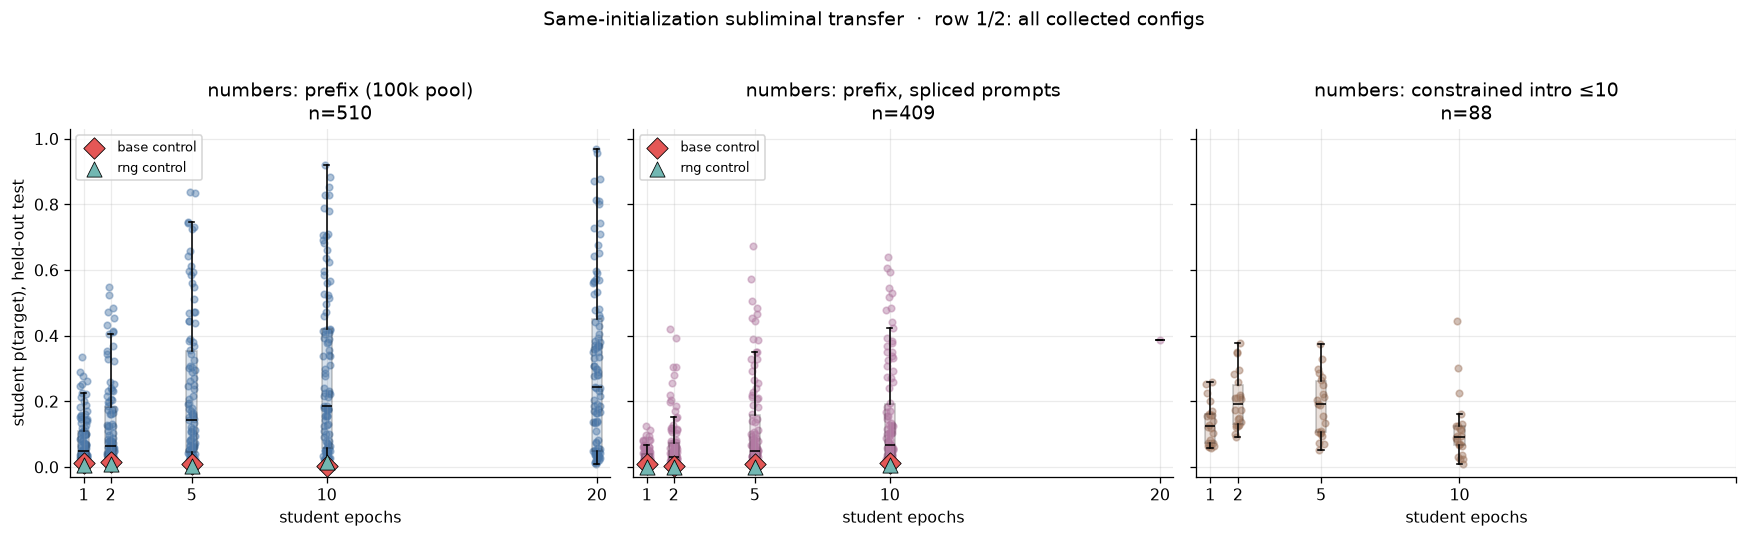

,n,treatment mean,treatment median,base student,mean Δ vs base,rng student,mean Δ vs rng
numbers,,,,,,,
prefix (100k pool),102,0.081,0.048,0.012,0.069,0.006,0.075
"prefix, spliced prompts",102,0.031,0.021,0.009,0.022,0.001,0.030
constrained intro ≤10,22,0.132,0.125,nan,nan,nan,nan


trained-student teacher-HP cells per mode: {'ex10-20_prefix_n100k': 102, 'ex10-20_prefix_n100k_spliced': 102, 'intro-u10_prefix_n10k': 22} |  shared across all 3: 22


In [3]:
coverage = pd.crosstab(wide.dataset, wide.student_epochs)
coverage.index = [LABEL.get(x,x) for x in coverage.index]
display(coverage.style.set_caption("Completed same-init configs"))
assert same.duplicated(["config_id","set"]).sum() == 0
print("missing teacher scores by set:")
display(same[same.teacher_p.isna()].groupby("set").size().rename("missing"))
print("teacher association signal:", TEACHER_SIGNAL_SET)
print("training rows:", sorted(wide.n_train.dropna().unique()))

def transfer_boxplots(df, datasets, *, suptitle, epochs=None):
    """Per-dataset held-out-test boxplots vs student dose (the Section-1 chart); reused across rows 1-3."""
    epochs = sorted(df.student_epochs.unique()) if epochs is None else epochs
    n = max(len(datasets), 1)
    fig, axs = plt.subplots(1,n,figsize=(5.1*n,4.5),sharey=True,squeeze=False)
    for ax, ds in zip(axs.ravel(),datasets):
        sub = df[df.dataset.eq(ds)]
        groups = [(ep,sub.loc[sub.student_epochs.eq(ep),"student_test"].dropna().values) for ep in epochs]
        groups = [(ep,v) for ep,v in groups if len(v)]
        if groups:
            ax.boxplot([v for _,v in groups],positions=[ep for ep,_ in groups],widths=.38,patch_artist=True,showfliers=False,
                       boxprops={"facecolor":COLOR.get(ds,"C0"),"alpha":.22},medianprops={"color":"black"})
            for ep,v in groups:
                jitter = np.linspace(-.13,.13,len(v)) if len(v)>1 else [0]
                ax.scatter(ep+jitter,v,s=17,alpha=.45,color=COLOR.get(ds,"C0"))
        if len(controls_wide):
            # Controls are backfilled at every student dose; plot each at its own epoch (dose-matched to the treatment).
            for source,marker,color in [("base","D","#e45756"),("rng","^","#72b7b2")]:
                cc=controls_wide[controls_wide.dataset.eq(ds)&controls_wide.source.eq(source)].dropna(subset=["student_test"])
                if len(cc): ax.scatter(cc.student_epochs,cc.student_test,marker=marker,s=90,color=color,edgecolor="black",lw=.5,zorder=5,label=f"{source} control")
        base=sub.untuned_test.dropna()
        if len(base): ax.axhline(base.iloc[0],color=".35",ls=":",label="untuned base")
        ax.set(title=f"numbers: {LABEL.get(ds,ds)}\nn={len(sub)}",xlabel="student epochs",xticks=epochs,ylim=(-.03,1.03))
        if ax.get_legend_handles_labels()[0]: ax.legend(fontsize=8,loc="upper left")  # skip empty legend (e.g. lineages with no controls/untuned baseline)
    axs[0,0].set_ylabel("student p(target), held-out test")
    fig.suptitle(suptitle,y=1.03); plt.tight_layout(); plt.show()

# Row 1 — every collected config, one box per number mode x student dose.
transfer_boxplots(wide, sorted(wide.dataset.unique()),
                  suptitle="Same-initialization subliminal transfer  ·  row 1/2: all collected configs")

# Matched Δ at 1 epoch: treatment@ep1 vs the DOSE-MATCHED (ep1) base/rng control. Controls now exist at every
# dose, so restrict to student_epochs==1 here; the assert then guards genuine duplicates (same source/dataset/dose).
matched=[]
for ds,sub in wide[wide.student_epochs.eq(1)].groupby("dataset"):
    row={"numbers":LABEL.get(ds,ds),"n":len(sub),"treatment mean":sub.student_test.mean(),"treatment median":sub.student_test.median()}
    for source in ("base","rng"):
        cc=(controls_wide[controls_wide.dataset.eq(ds)&controls_wide.source.eq(source)&controls_wide.student_epochs.eq(1)]
            if len(controls_wide) else pd.DataFrame())
        v=cc["student_test"].dropna() if len(cc) else pd.Series(dtype=float)
        assert len(v)<=1, f"multiple {source} ep1 controls for dataset {ds}: {v.tolist()}"
        row[f"{source} student"]=v.iloc[0] if len(v) else np.nan
        row[f"mean Δ vs {source}"]=row["treatment mean"]-row[f"{source} student"]
    matched.append(row)
display(pd.DataFrame(matched).set_index("numbers").style.format({c:"{:.3f}" for c in pd.DataFrame(matched).columns if c not in ("numbers","n")}))

# Number-generation modes compared in row 2 (same three as Section 6). Constrained decoding (intro-u10) students
# were trained only on a pre-selected subset of teachers correlated with stronger transfer, so row 1's constrained
# box is upward-biased. Row 2 restricts all three modes to the teacher-HP cells shared by every mode.
MODE_DATASETS    = ["ex10-20_prefix_n100k", "ex10-20_prefix_n100k_spliced", "intro-u10_prefix_n10k"]
CONSTRAINED_MODE = "intro-u10_prefix_n10k"
_mode_tags = {ds: set(wide.loc[wide.dataset.eq(ds), "teacher_tag"]) for ds in MODE_DATASETS}
SHARED_TAGS = set.intersection(*_mode_tags.values()) if _mode_tags else set()
print("trained-student teacher-HP cells per mode:", {ds: len(t) for ds, t in _mode_tags.items()},
      f"|  shared across all 3: {len(SHARED_TAGS)}")

**Row 2 — shared cells (apples-to-apples mode comparison).** Restricts `prefix`, `prefix-spliced`, and `constrained-intro` to the teacher-HP cells present in **all three** modes, so every box aggregates over an identical config set. This removes the selection bias from constrained decoding, whose students were trained only on teachers pre-selected for stronger transfer.

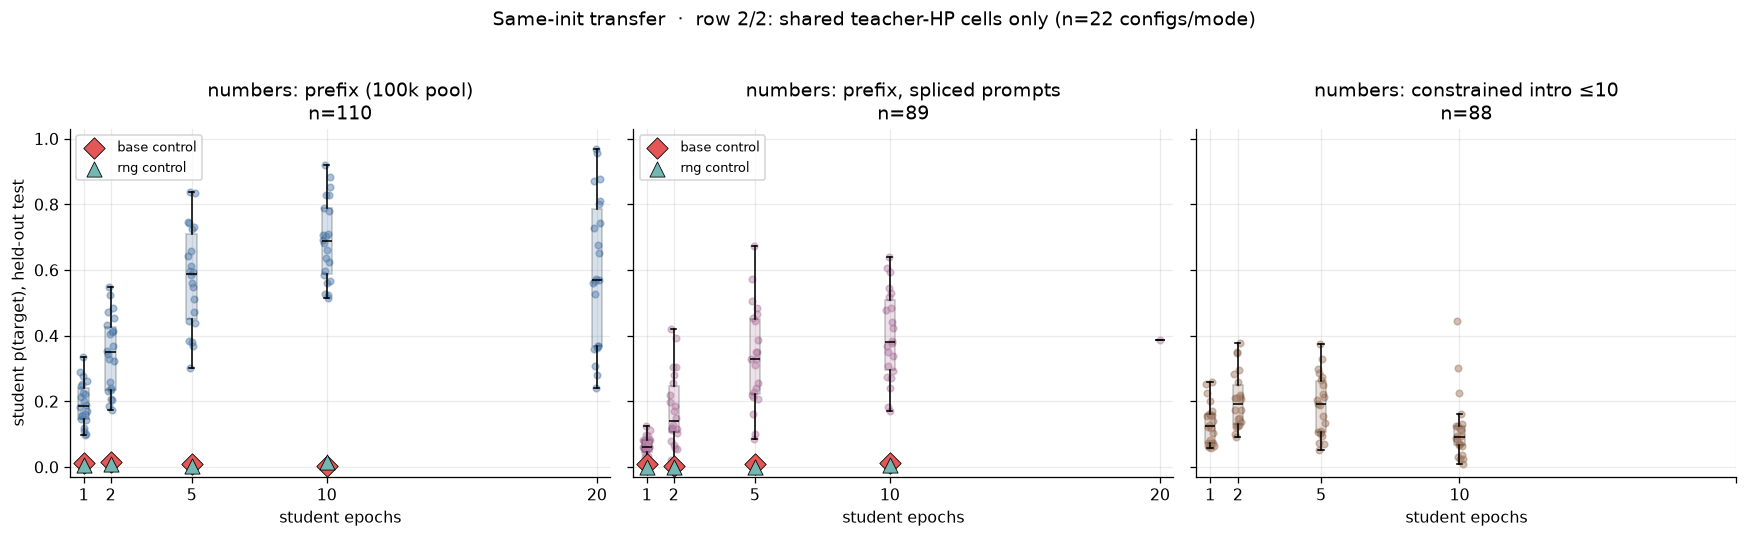

In [4]:
# Row 2 — the same boxplots restricted to teacher-HP cells present in ALL THREE number-gen modes, so prefix,
# prefix-spliced, and constrained-intro aggregate over an identical config set (removes the constrained-cell
# selection bias). This is the apples-to-apples version of row 1's mode comparison.
if SHARED_TAGS:
    row2 = wide[wide.dataset.isin(MODE_DATASETS) & wide.teacher_tag.isin(SHARED_TAGS)]
    transfer_boxplots(row2, MODE_DATASETS,
                      suptitle=f"Same-init transfer  ·  row 2/2: shared teacher-HP cells only "
                               f"(n={len(SHARED_TAGS)} configs/mode)")
else:
    print("no teacher-HP cell is shared across all three number-gen modes - row 2 skipped")

## 2. Student dose and teacher → student transfer

Dose-response includes only lineages completed at 1, 2, and 5 epochs. Shaded intervals describe cross-config variation, not seed uncertainty. The teacher signal is read straight from the source teacher's own eval — teacher `test` when available, otherwise teacher `validation` (the teacher artifacts carry no `test` set); student `test` remains the outcome. Spearman's ρ is associative, not causal.

226 complete lineages / 1007 students


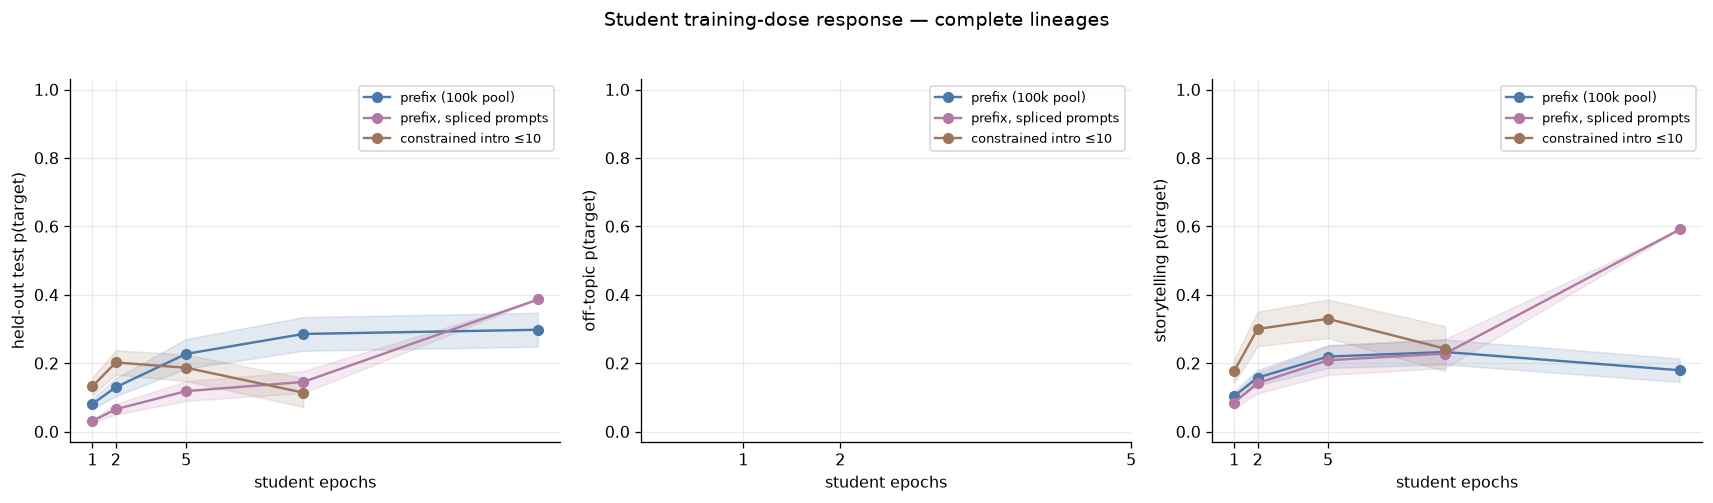

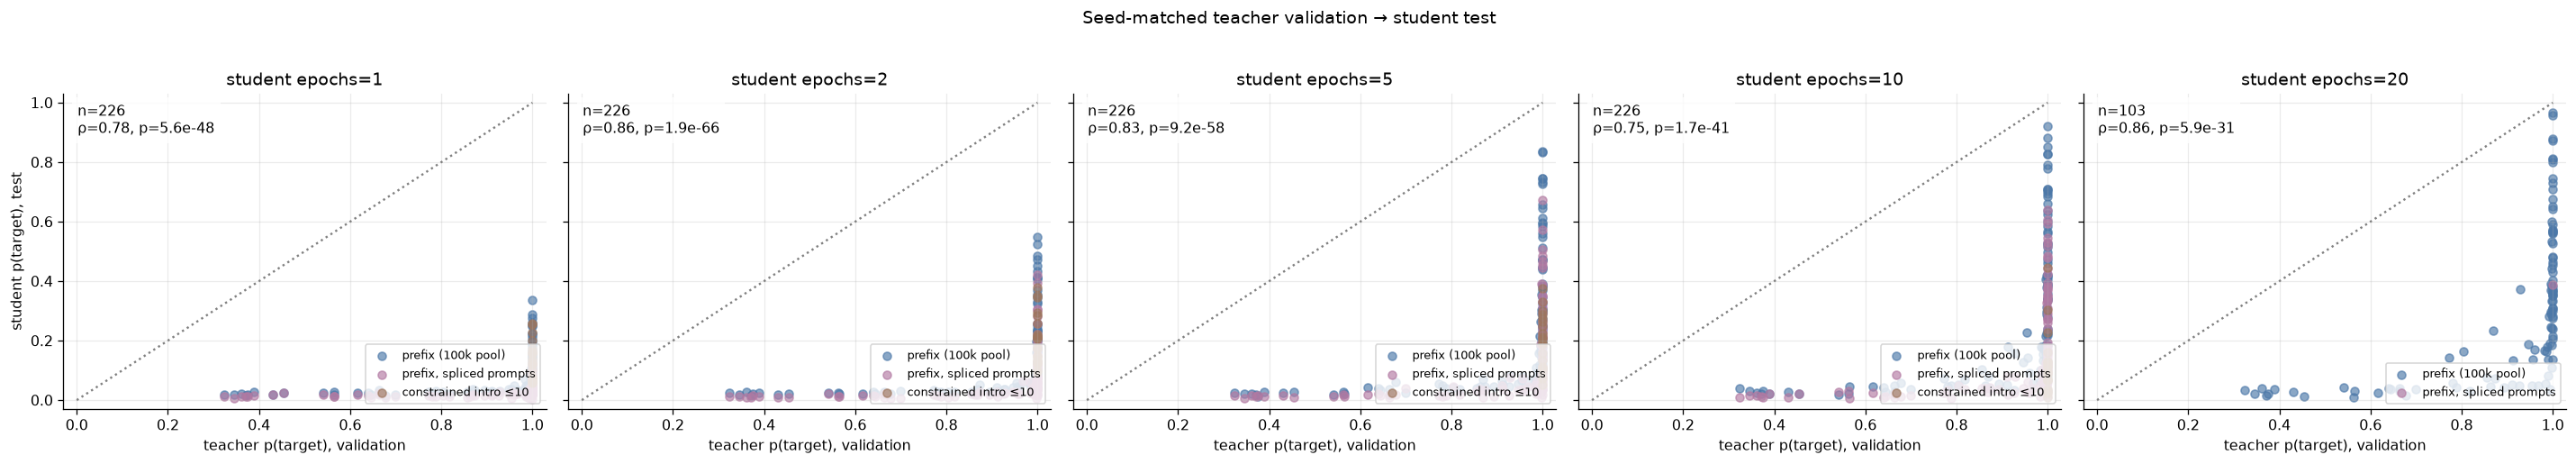

In [5]:
# `epochs` = the student-dose axis (was previously an undefined global on a clean run).
epochs = sorted(wide.student_epochs.unique())

complete = wide.groupby("lineage").student_epochs.agg(lambda x:{1,2,5}.issubset(set(x)))
paired = wide[wide.lineage.isin(complete[complete].index)]
print(f"{paired.lineage.nunique()} complete lineages / {len(paired)} students")
fig,axs=plt.subplots(1,3,figsize=(15,4.2))
for ax,(metric,label) in zip(axs,[("student_test","held-out test"),("student_off_topic","off-topic"),("student_storytelling","storytelling")]):
    aplots.dose_response(ax,paired,x="student_epochs",y=metric,group="dataset",colors=COLOR,labels=LABEL,ci=True)
    ax.set(xlabel="student epochs",ylabel=f"{label} p(target)",xticks=[1,2,5],ylim=(-.03,1.03)); ax.legend(fontsize=8)
fig.suptitle("Student training-dose response — complete lineages",y=1.03); plt.tight_layout(); plt.show()

fig,axs=plt.subplots(1,len(epochs),figsize=(5*len(epochs),4.3),sharex=True,sharey=True,squeeze=False)
for ax,ep in zip(axs.ravel(),epochs):
    sub=wide[wide.student_epochs.eq(ep)].dropna(subset=["teacher_signal","student_test"])
    for ds,d in sub.groupby("dataset"): ax.scatter(d.teacher_signal,d.student_test,s=32,alpha=.65,color=COLOR.get(ds),label=LABEL.get(ds,ds))
    rho,p=spearmanr(sub.teacher_signal,sub.student_test) if len(sub)>2 else (np.nan,np.nan); ax.plot([0,1],[0,1],color=".5",ls=":")
    ax.text(.03,.97,f"n={len(sub)}\nρ={rho:.2f}, p={p:.2g}",transform=ax.transAxes,va="top",bbox={"facecolor":"white","alpha":.8,"edgecolor":"none"})
    ax.set(title=f"student epochs={ep}",xlabel=f"teacher p(target), {TEACHER_SIGNAL_SET}",xlim=(-.03,1.03),ylim=(-.03,1.03)); ax.legend(fontsize=8,loc="lower right")
axs[0,0].set_ylabel("student p(target), test"); fig.suptitle(f"Seed-matched teacher {TEACHER_SIGNAL_SET} → student test",y=1.03); plt.tight_layout(); plt.show()

## 3. Teacher hyperparameter surface

Edit the dataset choice. One figure per animal (here just `dog`); **rows = student epochs**
(ascending), columns = teacher LR (ascending), so reading down a column shows how the same
teacher-HP surface sharpens with student dose. Within a figure each populated cell is a single
teacher run — a duplicate-key assert on `(animal, student_epochs, teacher_epochs, teacher_lora,
teacher_lr)` guarantees no pooling across runs. Rank/alpha and learning rate remain explicit.

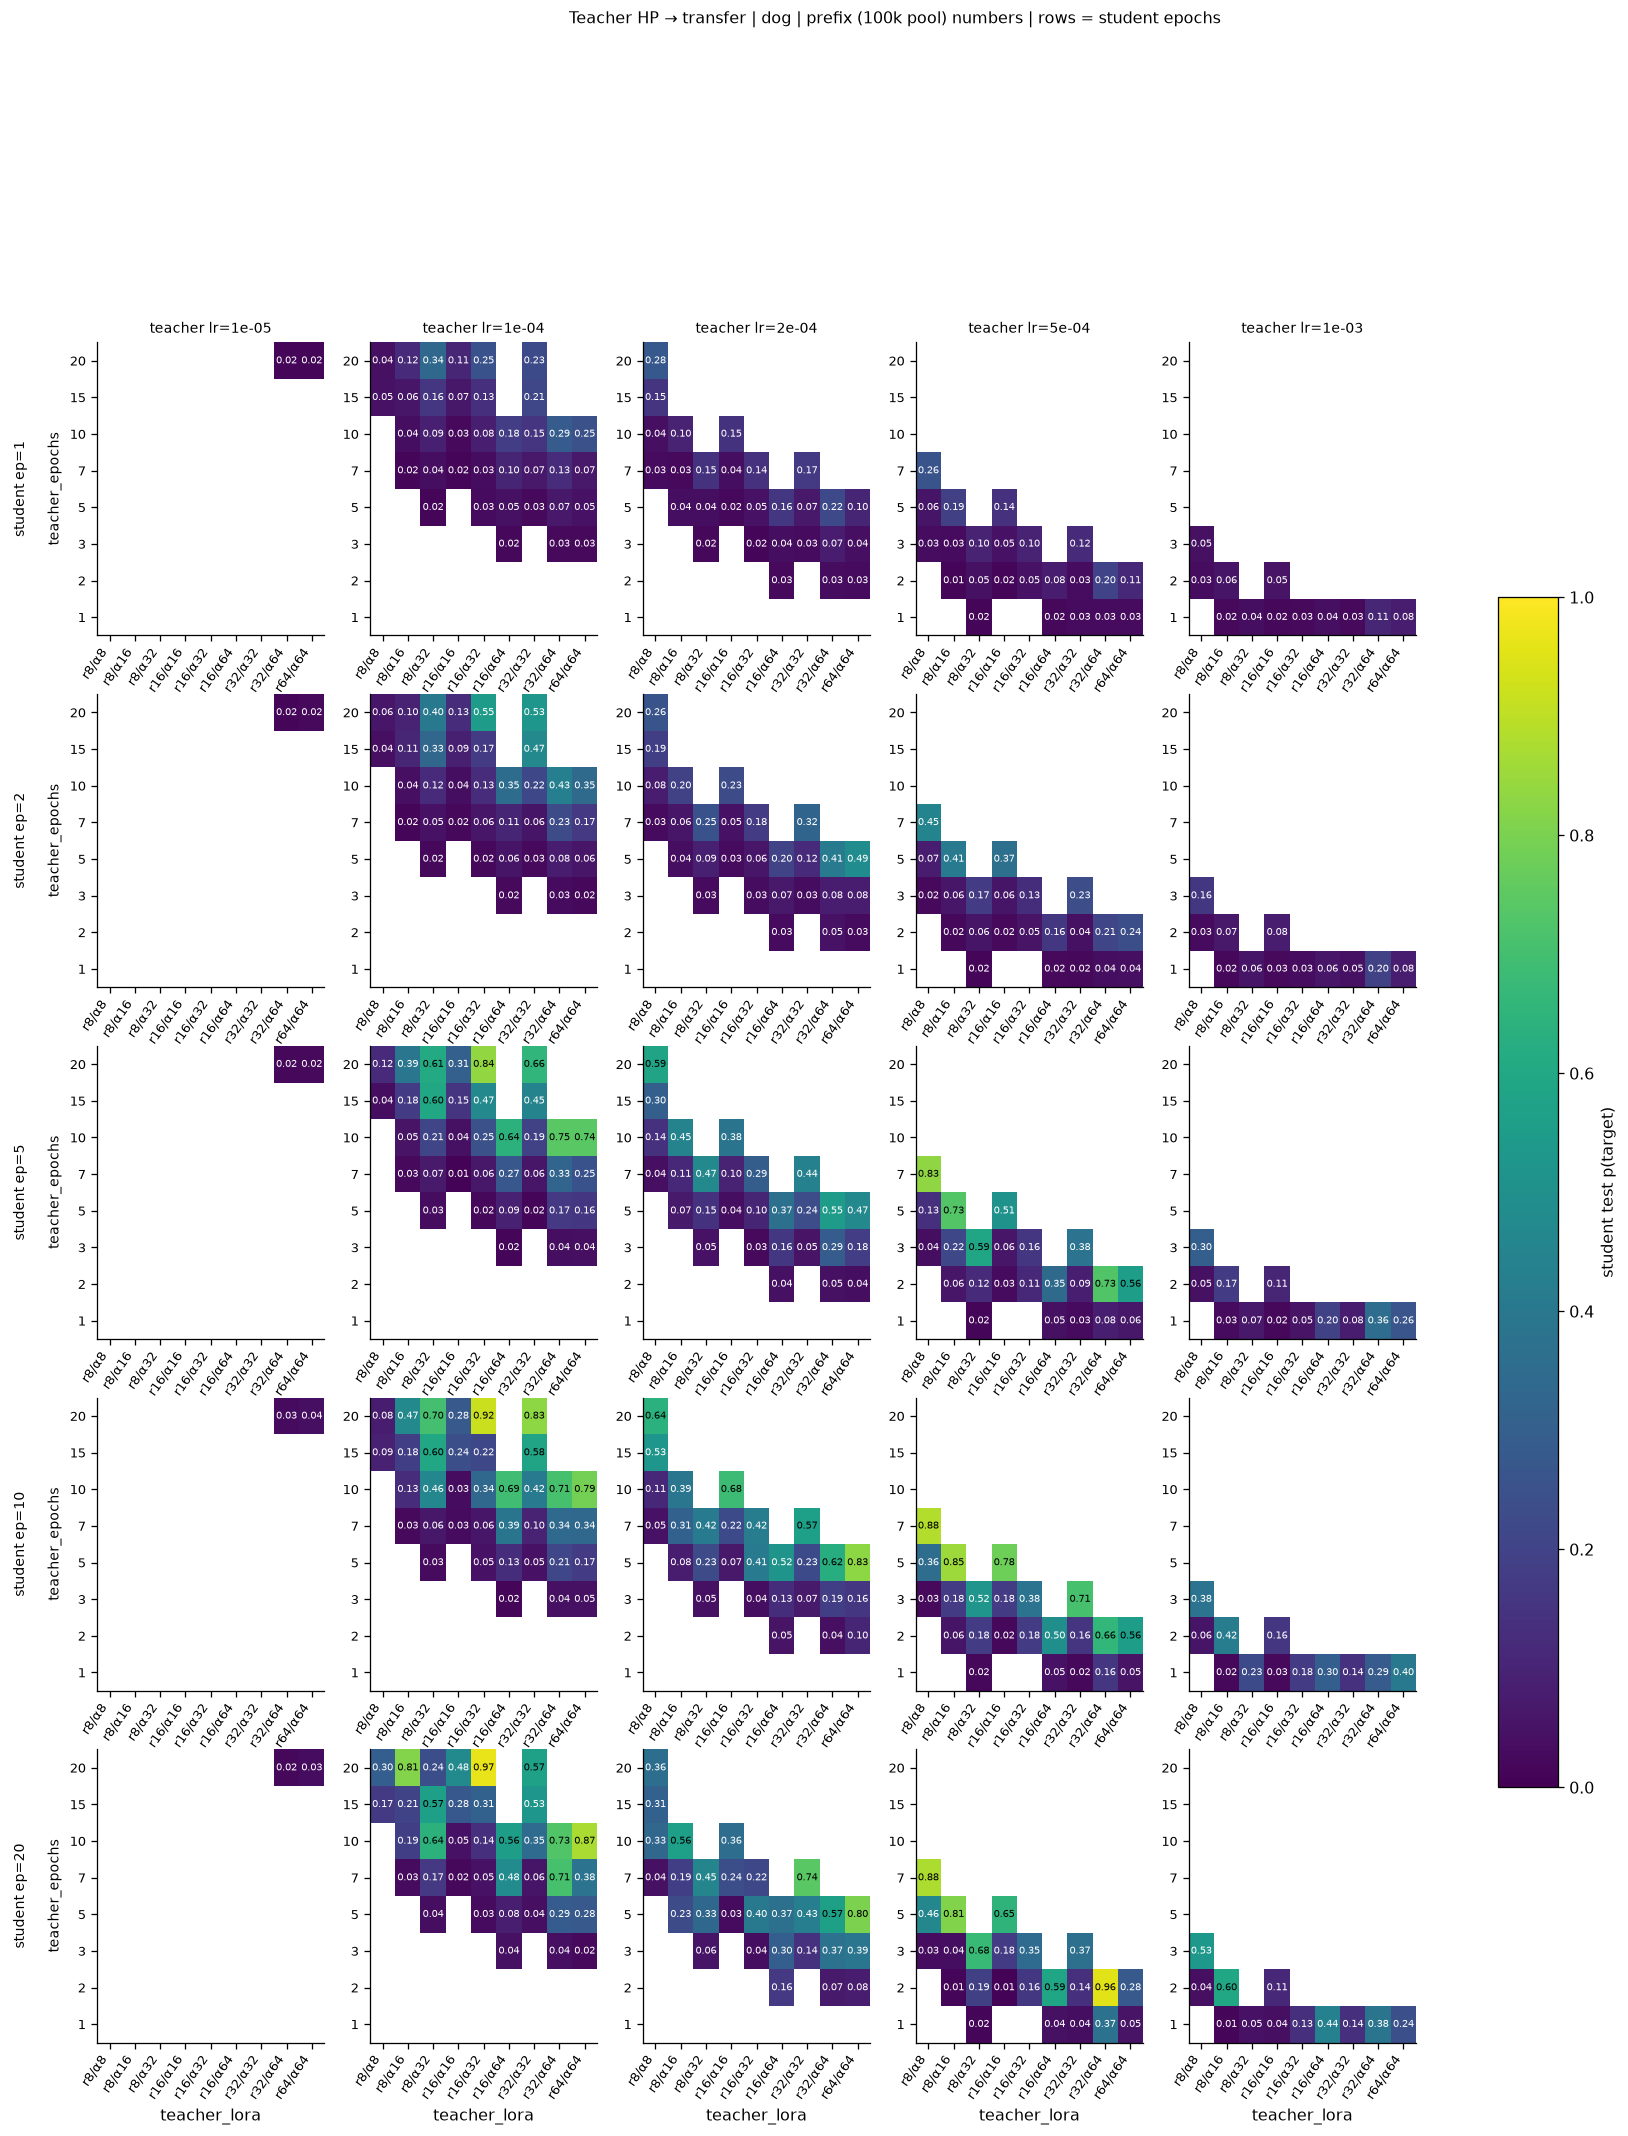

In [6]:
PRIMARY_DATASET, PRIMARY_STUDENT_EPOCH = "ex10-20_prefix_n100k", 5  # PRIMARY_STUDENT_EPOCH still pins §6's mode comparison
hp=wide[wide.dataset.eq(PRIMARY_DATASET)]
assert len(hp)
DUP_KEYS=["animal","student_epochs","teacher_epochs","teacher_lora","teacher_lr"]
assert not hp.duplicated(DUP_KEYS).any(), \
    f"duplicate teacher-HP keys would pool multiple runs per heatmap cell: {hp[hp.duplicated(DUP_KEYS,keep=False)][DUP_KEYS].to_dict('records')}"
loras=sorted(hp.teacher_lora.unique(),key=lambda x:tuple(map(int,re.findall(r"\d+",x))))
for animal in sorted(hp.animal.unique()):
    ha=hp[hp.animal.eq(animal)]
    _ = aplots.facet_grid_heatmaps(
        ha, row="teacher_epochs", col="teacher_lora", val="student_test",
        row_facet="student_epochs", col_facet="teacher_lr",
        orders={"teacher_lora": loras}, mid=0.55, cmap="viridis", vmin=0, vmax=1,
        cbar_label="student test p(target)",
        row_facet_label=lambda sep: f"student ep={sep}",
        col_facet_label=lambda lr: f"teacher lr={lr:.0e}",
        title=f"Teacher HP → transfer | {animal} | {LABEL.get(PRIMARY_DATASET)} numbers | rows = student epochs")

## 4. Specificity, OOD behavior, and ranked configs

High `test` with low `off_topic` is more specific. Storytelling is sampled and may be read as OOD generalization or leakage. The table's transparent ranking score is `test − off_topic`, not a definitive objective.

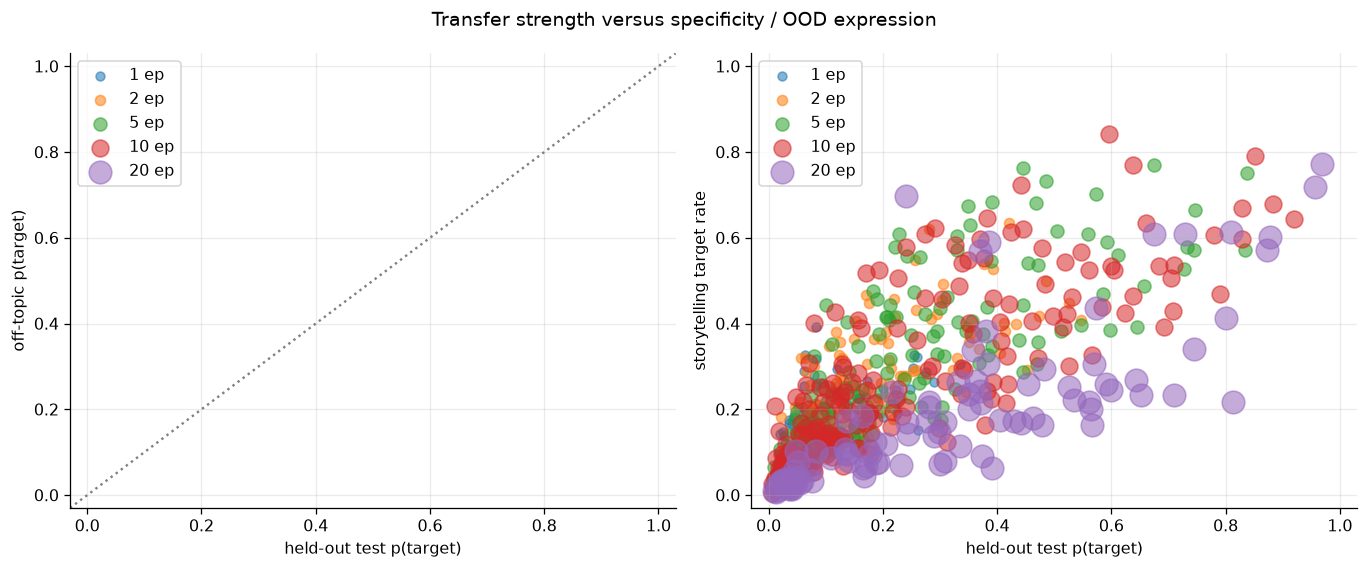

,teacher_tag,dataset,student ep,teacher validation,student_test,student_validation,student_off_topic,student_storytelling,test_minus_offtopic,test rank,loss
318,ep20_lr1e-4_r16a32,ex10-20_prefix_n100k,20,1.000,0.968,nan,nan,0.771,nan,1.0,1.370
496,ep2_lr5e-4_r32a64,ex10-20_prefix_n100k,20,1.000,0.956,nan,nan,0.718,nan,1.0,1.427
316,ep20_lr1e-4_r16a32,ex10-20_prefix_n100k,10,1.000,0.920,nan,nan,0.645,nan,1.0,1.781
994,ep7_lr5e-4_r8a8,ex10-20_prefix_n100k,10,1.000,0.883,nan,nan,0.679,nan,1.0,1.908
996,ep7_lr5e-4_r8a8,ex10-20_prefix_n100k,20,1.000,0.877,nan,nan,0.601,nan,1.0,1.366
55,ep10_lr1e-4_r64a64,ex10-20_prefix_n100k,20,1.000,0.872,nan,nan,0.572,nan,1.0,1.471
842,ep5_lr5e-4_r8a16,ex10-20_prefix_n100k,10,1.000,0.852,nan,nan,0.791,nan,1.0,1.781
320,ep20_lr1e-4_r16a32,ex10-20_prefix_n100k,5,1.000,0.838,nan,nan,0.751,nan,1.0,2.017
998,ep7_lr5e-4_r8a8,ex10-20_prefix_n100k,5,1.000,0.835,nan,nan,0.572,nan,1.0,1.985
798,ep5_lr2e-4_r64a64,ex10-20_prefix_n100k,10,1.000,0.828,nan,nan,0.671,nan,1.0,1.985


,count,mean,median
student_epochs,,,
1,226,0.063,0.036
2,226,0.108,0.058
5,226,0.174,0.094
10,226,0.206,0.114
20,103,0.299,0.245


Overall teacher validation ↔ student test association: ρ=0.742, p=6.98e-177
Best test−off-topic: ep20_lr1e-4_r16a32, prefix (100k pool), student ep=20, test=0.968, off-topic=nan, storytelling=0.771


In [7]:
fig,axs=plt.subplots(1,2,figsize=(12,5))
for ax,y,label in [(axs[0],"student_off_topic","off-topic p(target)"),(axs[1],"student_storytelling","storytelling target rate")]:
    for ep,sub in wide.groupby("student_epochs"): ax.scatter(sub.student_test,sub[y],s=22+9*ep,alpha=.55,label=f"{ep} ep")
    ax.set(xlabel="held-out test p(target)",ylabel=label,xlim=(-.03,1.03),ylim=(-.03,1.03)); ax.legend()
axs[0].axline((0,0),slope=1,color=".5",ls=":"); fig.suptitle("Transfer strength versus specificity / OOD expression"); plt.tight_layout(); plt.show()

cols=["teacher_tag","dataset","student_epochs","teacher_signal","student_test","student_validation","student_off_topic","student_storytelling","test_minus_offtopic","rank_test","loss"]
top=wide.sort_values(["test_minus_offtopic","student_test"],ascending=False)[cols].head(25).rename(columns={"student_epochs":"student ep","rank_test":"test rank","teacher_signal":f"teacher {TEACHER_SIGNAL_SET}"})
formats={c:"{:.3f}" for c in [f"teacher {TEACHER_SIGNAL_SET}","student_test","student_validation","student_off_topic","student_storytelling","test_minus_offtopic","loss"]}; formats["test rank"]="{:.1f}"
display(top.style.format(formats))

best=wide.sort_values(["test_minus_offtopic","student_test"],ascending=False).iloc[0]
dose=wide.groupby("student_epochs").student_test.agg(["count","mean","median"])
rho,p=spearmanr(wide.teacher_signal,wide.student_test,nan_policy="omit")
display(dose.style.format({"mean":"{:.3f}","median":"{:.3f}"}))
print(f"Overall teacher {TEACHER_SIGNAL_SET} ↔ student test association: ρ={rho:.3f}, p={p:.3g}")
print(f"Best test−off-topic: {best.teacher_tag}, {LABEL.get(best.dataset,best.dataset)}, student ep={best.student_epochs:g}, test={best.student_test:.3f}, off-topic={best.student_off_topic:.3f}, storytelling={best.student_storytelling:.3f}")

## 5. Does the base checkpoint set same-init transfer strength? (`cat`, `pythia-160m` vs `pythia-160m-data-seed1`)

Sections 1–4 are scoped to `dog` + the original `pythia-160m`. This section steps sideways to the **`cat`** runs, the only subject where the original `pythia-160m` has a matched PolyPythia re-run (`data-seed1`) to compare against. The question: is same-init transfer strength a property of the *base checkpoint* — or of what happened to be run? The two bases weren't run identically (`data-seed1` also spans `full10`/`full10_3digit`, and its prefix numbers were drawn from a larger candidate pool), so pooling them naively is apples-to-oranges.

This section makes the comparison **fair** by matching everything mechanical and letting only the base model vary:

- **number mode** fixed to the `ex10-20_prefix` template — both bases train on **10 000** prefix rows (the candidate pools differ, 40k for the original vs 100k for `data-seed1`, but the trained row count and format are identical),
- **teacher HP grid** intersected (only teacher configs run for *both* bases),
- **student dose** compared epoch-by-epoch,
- **student LoRA** identical (`lr1e-4_r8a32`), **teacher seed 1 / ft seed 1**, both **same-init** (student initialized from the same checkpoint that generated its numbers).

The two right-hand panels are **controls**: the teacher's own trait strength (are the teachers equally good?) and the student's final train loss (did `pythia-160m` just fail to fit the numbers?). If both controls match, the residual gap is a genuine base-model / pretraining-run effect on the covert number→preference channel.

configs per base: {'pythia-160m': 336, 'pythia-160m-data-seed1': 432} | shared teacher HPs: 84
candidate pool per base: {'pythia-160m': ['ex10-20_prefix_n40k'], 'pythia-160m-data-seed1': ['ex10-20_prefix_n100k']} | trained rows: [np.int64(10000)]


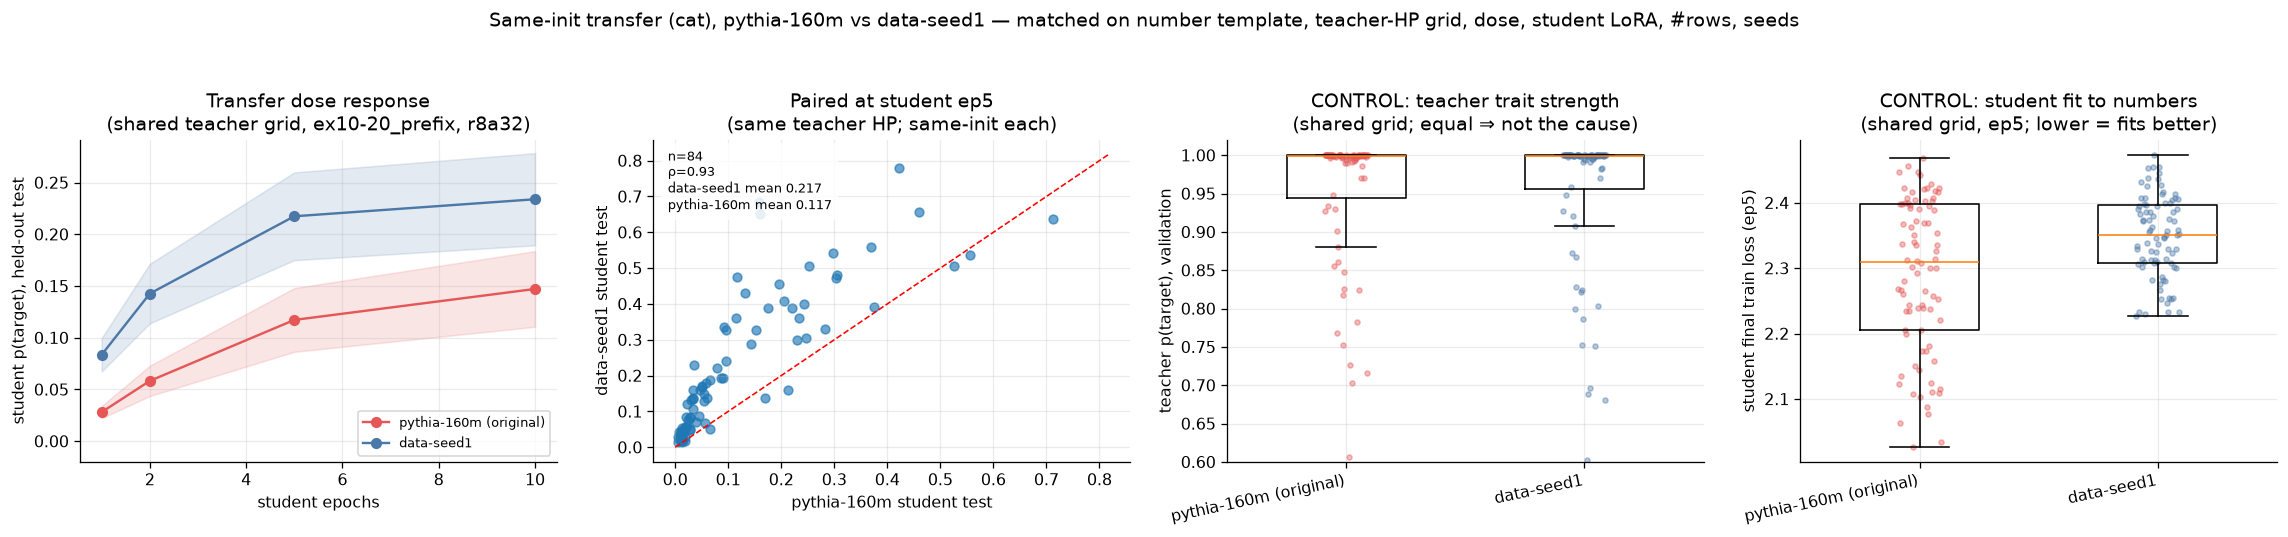

,n shared teacher HP,pythia-160m mean,data-seed1 mean,ratio 160m/seed1,paired Δ (160m−seed1)
student ep,,,,,
1,84,0.028,0.084,0.337,-0.055
2,84,0.058,0.143,0.409,-0.084
5,84,0.117,0.217,0.539,-0.100
10,84,0.147,0.234,0.629,-0.087


CONTROLS on the shared grid — why the gap is not an artifact:
  teacher validation p(target):  pythia-160m=0.941  data-seed1=0.938   (teachers equally trait-loaded on the matched grid)
  student final train loss (ep5): pythia-160m=2.291  data-seed1=2.349   (pythia-160m fits the numbers at least as well)
  matched on: number template=ex10-20_prefix (pools n40k vs n100k, 10000 trained rows), student LoRA=r8a32/lr1e-4, tseed1/ftseed1, same-init


In [8]:
# Compare same-init transfer for two bases (cat), matched on everything mechanical so only the base model differs.
CMP_ANIMAL = "cat"   # the only subject with both the original pythia-160m and its data-seed1 re-run
CMP_BASES = ["pythia-160m", "pythia-160m-data-seed1"]
BASE_NAME = {"pythia-160m":"pythia-160m (original)", "pythia-160m-data-seed1":"data-seed1"}
BASE_C    = {"pythia-160m":"#e45756", "pythia-160m-data-seed1":"#4c78a8"}
CMP_MODE  = "ex10-20_prefix"   # match on the prefix template; the two bases differ only in candidate pool (n40k vs n100k), both train 10k rows
A, B      = "pythia-160m", "pythia-160m-data-seed1"

t = treatments_all
c = t[t["set"].eq("test") & t.same_init.eq(True) & t.animal.eq(CMP_ANIMAL) & t.teacher_seed.eq(TEACHER_SEED) &
      t.student_seeds.map(lambda s: s == (STUDENT_SEED,)) & t.dataset.str.startswith(CMP_MODE) &
      t.student_rank.eq(8) & t.student_alpha.eq(32) & np.isclose(t.student_lr, 1e-4) &
      t.model.isin(CMP_BASES)].drop_duplicates("config_id").rename(columns={"p":"student_test"}).copy()
present = [b for b in CMP_BASES if b in set(c.model)]
# Teacher HP tags run for BOTH bases (dose-independent) — every matched panel/table below restricts to these.
SHARED = sorted(set(c.loc[c.model.eq(A),"teacher_tag"]) & set(c.loc[c.model.eq(B),"teacher_tag"])) if len(present)==2 else []
print("configs per base:", {b: int(c.model.eq(b).sum()) for b in present}, "| shared teacher HPs:", len(SHARED))
print("candidate pool per base:", {b: sorted(c.loc[c.model.eq(b),"dataset"].unique()) for b in present},
      "| trained rows:", sorted(c.n_train.dropna().unique()))
cs = c[c.teacher_tag.isin(SHARED)]   # matched slice: only teacher HPs run for both bases

fig, axs = plt.subplots(1, 4, figsize=(20, 4.4))

# (A) transfer dose response on the shared teacher grid: mean held-out test vs student epochs, per base
ax = axs[0]
aplots.dose_response(ax, cs, x="student_epochs", y="student_test", group="model",
                     order=present, colors=BASE_C, labels=BASE_NAME, ci=True)
ax.set(xlabel="student epochs", ylabel="student p(target), held-out test",
       title=f"Transfer dose response\n(shared teacher grid, {CMP_MODE}, r8a32)"); ax.legend(fontsize=8); ax.set_ylim(bottom=-.02)

# (B) paired per-teacher-config at ep5 on the shared teacher grid
ax = axs[1]
if len(present) == 2:
    ep = 5
    a  = cs[cs.model.eq(A) & cs.student_epochs.eq(ep)].set_index("teacher_tag").student_test
    bb = cs[cs.model.eq(B) & cs.student_epochs.eq(ep)].set_index("teacher_tag").student_test
    sh = a.index.intersection(bb.index)
    lim = float(max(a[sh].max(), bb[sh].max()))*1.05
    aplots.identity_scatter(ax, pd.DataFrame({"pythia-160m": a[sh], "data-seed1": bb[sh]}),
                            x="pythia-160m", y="data-seed1", s=30, alpha=.65, stat="spearman",
                            textbox=True, title_stats=False, diag_lim=(0, lim),
                            extra_lines=[f"data-seed1 mean {bb[sh].mean():.3f}",
                                         f"pythia-160m mean {a[sh].mean():.3f}"])
    ax.set(xlabel="pythia-160m student test", ylabel="data-seed1 student test",
           title=f"Paired at student ep{ep}\n(same teacher HP; same-init each)")

# (C) CONTROL — teacher trait strength on the SHARED grid (one value per shared teacher HP, dose-independent)
ax = axs[2]
tvals = cs.drop_duplicates(["model","teacher_tag"])
aplots.strip_box(ax, [tvals.loc[tvals.model.eq(b),"teacher_sig_validation"].dropna().values for b in present],
                 [BASE_NAME[b] for b in present], colors=[BASE_C[b] for b in present],
                 s=10, alpha=.4, rotation=12)
ax.set(ylim=(0.6,1.02), ylabel="teacher p(target), validation",
       title="CONTROL: teacher trait strength\n(shared grid; equal ⇒ not the cause)")

# (D) CONTROL — student fit at a common dose (ep5) on the shared grid: did pythia-160m under-fit the numbers?
ax = axs[3]
fit = cs[cs.student_epochs.eq(5)]
aplots.strip_box(ax, [fit.loc[fit.model.eq(b),"loss"].dropna().values for b in present],
                 [BASE_NAME[b] for b in present], colors=[BASE_C[b] for b in present],
                 s=10, alpha=.4, rotation=12)
ax.set(ylabel="student final train loss (ep5)",
       title="CONTROL: student fit to numbers\n(shared grid, ep5; lower = fits better)")

fig.suptitle(f"Same-init transfer ({CMP_ANIMAL}), pythia-160m vs data-seed1 — matched on number template, teacher-HP grid, dose, student LoRA, #rows, seeds", y=1.05)
plt.tight_layout(); plt.show()

# ---- matched summary on shared teacher HPs, per dose ----
recs = []
for ep in sorted(set(cs[cs.model.eq(A)].student_epochs) & set(cs[cs.model.eq(B)].student_epochs)):
    a  = cs[cs.model.eq(A) & cs.student_epochs.eq(ep)].set_index("teacher_tag").student_test
    bb = cs[cs.model.eq(B) & cs.student_epochs.eq(ep)].set_index("teacher_tag").student_test
    sh = a.index.intersection(bb.index)
    recs.append({"student ep":ep, "n shared teacher HP":len(sh),
                 "pythia-160m mean":a[sh].mean(), "data-seed1 mean":bb[sh].mean(),
                 "ratio 160m/seed1":a[sh].mean()/bb[sh].mean(), "paired Δ (160m−seed1)":(a[sh]-bb[sh]).mean()})
tbl = pd.DataFrame(recs).set_index("student ep")
display(tbl.style.format({k:"{:.3f}" for k in tbl.columns if k!="n shared teacher HP"})
        .set_caption(f"Matched same-init transfer ({CMP_ANIMAL}) on {len(SHARED)} shared teacher HPs ({CMP_MODE}, student r8a32)"))

# Controls computed on the SAME matched slice, so they actually license the "not an artifact" claim.
tv  = lambda b: cs.drop_duplicates(["model","teacher_tag"]).pipe(lambda d: d.loc[d.model.eq(b),"teacher_sig_validation"]).mean()
ls5 = lambda b: fit.loc[fit.model.eq(b),"loss"].mean()
print("CONTROLS on the shared grid — why the gap is not an artifact:")
print(f"  teacher validation p(target):  pythia-160m={tv(A):.3f}  data-seed1={tv(B):.3f}   (teachers equally trait-loaded on the matched grid)")
print(f"  student final train loss (ep5): pythia-160m={ls5(A):.3f}  data-seed1={ls5(B):.3f}   (pythia-160m fits the numbers at least as well)")
print(f"  matched on: number template={CMP_MODE} (pools n40k vs n100k, 10000 trained rows), student LoRA=r8a32/lr1e-4, tseed1/ftseed1, same-init")

### What the comparison shows

**The gap is real and dose-robust.** Matched on the number template, the shared teacher-HP grid, dose, and student LoRA, `data-seed1` transfers ~2–3× more than `pythia-160m` at every student dose (≈0.10 vs 0.03 at ep1, 0.17 vs 0.07 at ep2, 0.27 vs 0.14 at ep5 — `pythia-160m` ≈ 0.3–0.5× of `data-seed1`). In the paired panel almost every point sits **above** the identity line: for the *same* teacher hyperparameters, the `data-seed1` same-init student picks up more of the animal preference.

**It is not a teacher-strength difference.** On the shared grid both teachers reach ≈0.99 validation p(target) — the explicit trait is equally strong in both. What differs is how much of that trait leaks through the number channel, not how much trait the teacher has.

**It is not under-fitting.** `pythia-160m` students reach a *lower* final train loss (they fit the number sequences at least as well), yet transfer less. Weak transfer is therefore not "the student failed to learn the numbers."

**Everything mechanical is held equal** — both bases train on 10 000 `ex10-20_prefix` rows (the candidate pools differ, 40k for the original vs 100k for `data-seed1`, but the trained row count and format are identical), same student LoRA (`r8a32`, `lr1e-4`), teacher seed 1 / ft seed 1, same-init on both sides.

### Why — the likely cause

With teacher trait, number mode, dose, LoRA, data volume, and student fit all controlled, the residual is a **property of the pretrained checkpoint itself**. The original Pythia-160m and the PolyPythia `data-seed1` re-run are *different pretraining trajectories* (a different data-ordering seed), so their internal representation geometry differs.

Read through the steering-vector-distillation account (Blank et al.): subliminal transfer works because the teacher's trait fine-tune induces a direction that bleeds into the number-token logits, and a **same-init** student re-absorbs that direction through gradient alignment on the numbers. How strongly the animal-preference direction is entangled with the number distribution — the *gain* of that covert channel — is set by the base checkpoint's geometry. `data-seed1` evidently has a higher-gain channel than the original Pythia-160m, even though the two models are the same size and the teacher expresses the trait equally. That the `pythia-160m` gap is a *uniform downward shift* across teacher epochs and student doses (rather than a threshold that never fires) is consistent with a channel-gain difference, not a broken pipeline.

### Caveats before over-reading

- **One animal (cat), one teacher seed, one student seed** — these are point estimates; add student/teacher seeds before treating the ~2–3× ratio as precise. (The `dog` same-init runs in Sections 1–4 use the original `pythia-160m` only, with no `data-seed1` counterpart to close the base loop.)
- **`test` only** — `pythia-160m` students were not scored on `off_topic`/`validation`, so specificity isn't controlled here; a backfill would let us check the gap isn't just noisier off-target expression.
- **Untuned baseline not recorded for `pythia-160m`** (`base_p` is NaN; `data-seed1` ≈ 0.005). Both are 160m models trained from scratch so a near-zero baseline is expected, but backfilling the base-control eval would close this off as an alternative explanation.
- **Candidate pools differ** (40k for the original vs 100k for `data-seed1`), though both train the same 10 000 `ex10-20_prefix` rows; the base gap could also differ under `full10` modes, which the original `pythia-160m` hasn't been run on.

### Interpretation checklist

- Use held-out `test`, not teacher-trained `favorite`, for the main transfer claim.
- Report `off_topic` beside `test`; high values on both are not specific.
- Treat `dislike` as a valence/lexical control.
- Compare trained treatment and control students only when number mode, base, epoch dose, and seed policy match.
- Add multiple student seeds before reporting seed-level uncertainty or stable treatment-minus-control intervals.
- Storytelling is sampled and noisier than the exact-probability prompt sets.

## 5b. Three same-init experiments side by side: the two `cat` runs + `dog` × `pythia-160m`

§5's matched comparison, extended with this notebook's own §1–4 subject (**`dog` on the original
`pythia-160m`**) as a third experiment next to `cat`/`pythia-160m` and `cat`/`data-seed1`.
Matching is the same — `ex10-20_prefix` template (plain only; dog's `_spliced` sibling excluded),
**10 000** trained rows, student LoRA `r8a32`/`lr1e-4`, teacher seed 1 / ft seed 1, same-init —
and the teacher-HP grid is intersected across **all three** experiments, so every panel/table
below averages the identical teacher configs.

Read it with the animal difference in mind: `dog` is a **different trait**, so cross-animal
*levels* are descriptive, not another controlled contrast. The informative view is the
**same-base pairing** (panel B): for the *same* original checkpoint and the *same* teacher HP,
does the weak-`cat` channel look weak for `dog` too — i.e. is the §5 gap a property of the
checkpoint, or of the checkpoint × trait pair?

shared teacher HPs across all three: 84 | configs per experiment: {'cat / pythia-160m': 336, 'cat / data-seed1': 336, 'dog / pythia-160m': 420}
pools: {'cat / pythia-160m': ['ex10-20_prefix_n40k'], 'cat / data-seed1': ['ex10-20_prefix_n100k'], 'dog / pythia-160m': ['ex10-20_prefix_n100k']} | trained rows: [np.int64(10000)]


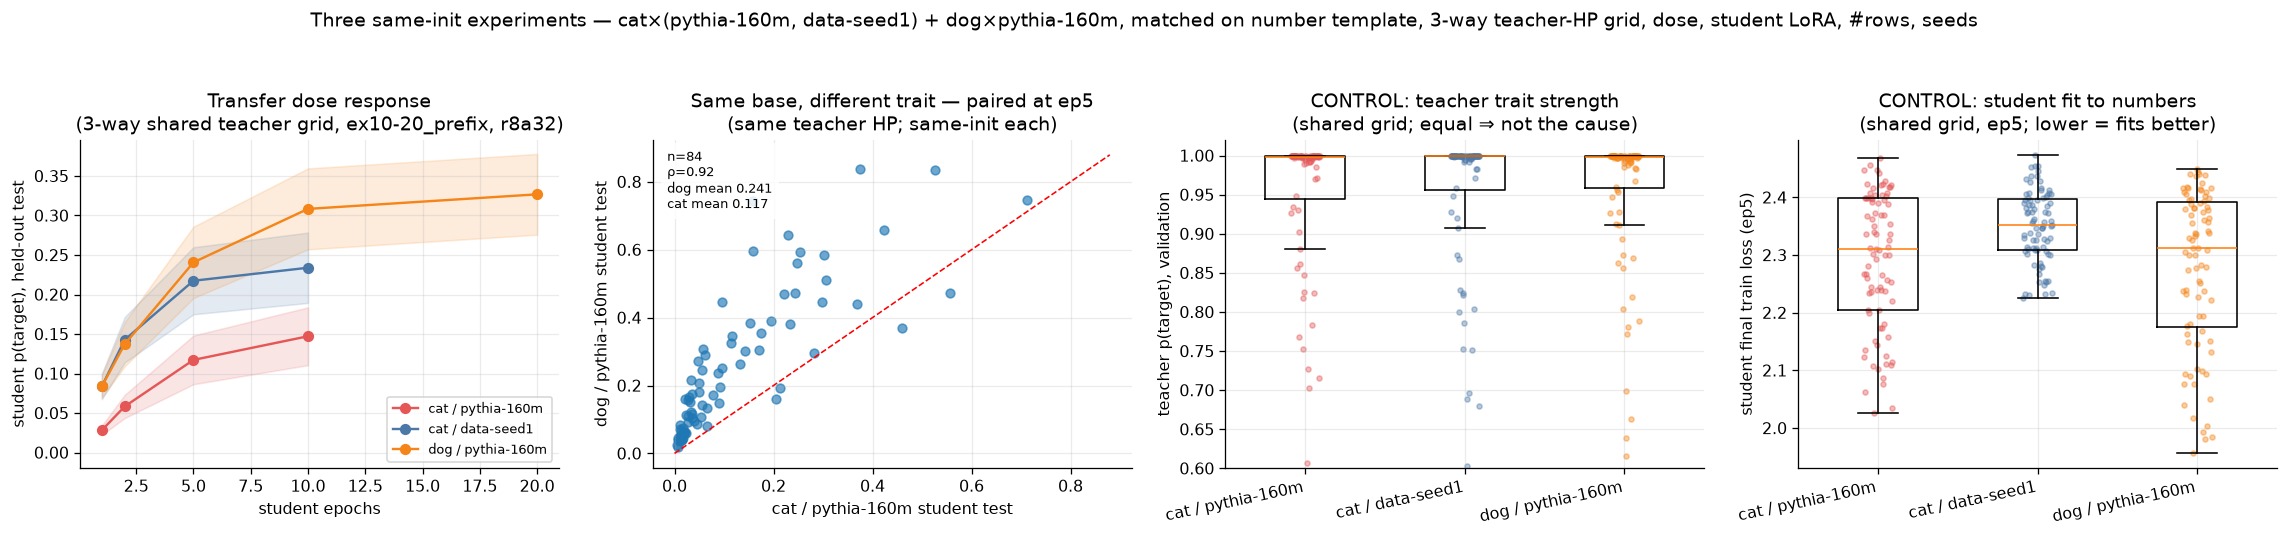

,cat / pythia-160m,n cat / pythia-160m,cat / data-seed1,n cat / data-seed1,dog / pythia-160m,n dog / pythia-160m
student ep,,,,,,
1,0.028,84,0.084,84,0.084,84
2,0.058,84,0.143,84,0.137,84
5,0.117,84,0.217,84,0.241,84
10,0.147,84,0.234,84,0.308,84
20,—,0,—,0,0.327,84


Reading (teacher strength and student fit are matched, so either way it is not an artifact):
  - dog tracks cat/pythia-160m (both low)  -> the §5 gap is a property of the CHECKPOINT alone;
  - dog instead reaches data-seed1-like levels -> the covert-channel gain is set by the
    checkpoint × trait pair (direction-specific geometry), not by the checkpoint globally.


In [9]:
# Three same-init experiments on one matched footing; teacher-HP grid intersected across all three.
EXPS  = [("cat", "pythia-160m"), ("cat", "pythia-160m-data-seed1"), ("dog", "pythia-160m")]
EXP_NAME = {EXPS[0]: "cat / pythia-160m", EXPS[1]: "cat / data-seed1", EXPS[2]: "dog / pythia-160m"}
EXP_C    = {EXPS[0]: "#e45756", EXPS[1]: "#4c78a8", EXPS[2]: "#f58518"}

t = treatments_all
c3 = t[t["set"].eq("test") & t.same_init.eq(True) & t.teacher_seed.eq(TEACHER_SEED) &
       t.student_seeds.map(lambda s: s == (STUDENT_SEED,)) & t.dataset.str.startswith("ex10-20_prefix") &
       ~t.dataset.str.endswith("_spliced") &   # dog also has a spliced sibling — matched slice is plain prefix only
       t.student_rank.eq(8) & t.student_alpha.eq(32) & np.isclose(t.student_lr, 1e-4)
      ].drop_duplicates("config_id").rename(columns={"p": "student_test"}).copy()
c3["exp"] = list(zip(c3.animal, c3.model))
c3 = c3[c3["exp"].isin(EXPS)]
SHARED3 = sorted(set.intersection(*[set(c3.loc[c3["exp"].isin([e]), "teacher_tag"]) for e in EXPS]))
assert SHARED3, "no teacher HP shared by all three experiments"
cs3 = c3[c3.teacher_tag.isin(SHARED3)]
print(f"shared teacher HPs across all three: {len(SHARED3)} | configs per experiment:",
      {EXP_NAME[e]: int(cs3["exp"].isin([e]).sum()) for e in EXPS})
print("pools:", {EXP_NAME[e]: sorted(cs3.loc[cs3["exp"].isin([e]), "dataset"].unique()) for e in EXPS},
      "| trained rows:", sorted(cs3.n_train.dropna().unique()))

fig, axs = plt.subplots(1, 4, figsize=(20, 4.4))

# (A) transfer dose response on the 3-way shared teacher grid
ax = axs[0]
aplots.dose_response(ax, cs3, x="student_epochs", y="student_test", group="exp",
                     order=EXPS, colors=EXP_C, labels=EXP_NAME, ci=True)
ax.set(xlabel="student epochs", ylabel="student p(target), held-out test",
       title="Transfer dose response\n(3-way shared teacher grid, ex10-20_prefix, r8a32)")
ax.legend(fontsize=8); ax.set_ylim(bottom=-.02)

# (B) SAME BASE, different trait — paired per teacher HP at ep5: cat vs dog on the original checkpoint.
ax = axs[1]
ep = 5
a  = cs3[cs3["exp"].isin([EXPS[0]]) & cs3.student_epochs.eq(ep)].set_index("teacher_tag").student_test
d  = cs3[cs3["exp"].isin([EXPS[2]]) & cs3.student_epochs.eq(ep)].set_index("teacher_tag").student_test
sh = a.index.intersection(d.index)
lim = float(max(a[sh].max(), d[sh].max())) * 1.05
aplots.identity_scatter(ax, pd.DataFrame({"cat": a[sh], "dog": d[sh]}),
                        x="cat", y="dog", s=30, alpha=.65, stat="spearman", textbox=True,
                        title_stats=False, diag_lim=(0, lim),
                        extra_lines=[f"dog mean {d[sh].mean():.3f}", f"cat mean {a[sh].mean():.3f}"])
ax.set(xlabel="cat / pythia-160m student test", ylabel="dog / pythia-160m student test",
       title=f"Same base, different trait — paired at ep{ep}\n(same teacher HP; same-init each)")

# (C) CONTROL — teacher trait strength on the shared grid (one value per teacher HP, dose-independent)
ax = axs[2]
tvals = cs3.drop_duplicates(["exp", "teacher_tag"])
aplots.strip_box(ax, [tvals.loc[tvals["exp"].isin([e]), "teacher_sig_validation"].dropna().values for e in EXPS],
                 [EXP_NAME[e] for e in EXPS], colors=[EXP_C[e] for e in EXPS],
                 s=10, alpha=.4, rotation=12)
ax.set(ylim=(0.6, 1.02), ylabel="teacher p(target), validation",
       title="CONTROL: teacher trait strength\n(shared grid; equal ⇒ not the cause)")

# (D) CONTROL — student fit at ep5 on the shared grid
ax = axs[3]
fit3 = cs3[cs3.student_epochs.eq(5)]
aplots.strip_box(ax, [fit3.loc[fit3["exp"].isin([e]), "loss"].dropna().values for e in EXPS],
                 [EXP_NAME[e] for e in EXPS], colors=[EXP_C[e] for e in EXPS],
                 s=10, alpha=.4, rotation=12)
ax.set(ylabel="student final train loss (ep5)",
       title="CONTROL: student fit to numbers\n(shared grid, ep5; lower = fits better)")

fig.suptitle("Three same-init experiments — cat×(pythia-160m, data-seed1) + dog×pythia-160m, "
             "matched on number template, 3-way teacher-HP grid, dose, student LoRA, #rows, seeds", y=1.05)
plt.tight_layout(); plt.show()

# ---- per-dose summary on the 3-way shared grid (cat/data-seed1 has no ep10 → NaN there) ----
recs = []
for ep in sorted(cs3.student_epochs.unique()):
    row = {"student ep": ep}
    for e in EXPS:
        v = cs3[cs3["exp"].isin([e]) & cs3.student_epochs.eq(ep)].student_test
        row[EXP_NAME[e]] = v.mean() if len(v) else np.nan
        row[f"n {EXP_NAME[e]}"] = len(v)
    recs.append(row)
tbl3 = pd.DataFrame(recs).set_index("student ep")
display(tbl3.style.format({EXP_NAME[e]: "{:.3f}" for e in EXPS}, na_rep="—")
        .set_caption(f"Same-init transfer, three experiments on {len(SHARED3)} 3-way shared teacher HPs "
                     "(ex10-20_prefix, student r8a32/lr1e-4)"))
print("Reading (teacher strength and student fit are matched, so either way it is not an artifact):")
print("  - dog tracks cat/pythia-160m (both low)  -> the §5 gap is a property of the CHECKPOINT alone;")
print("  - dog instead reaches data-seed1-like levels -> the covert-channel gain is set by the")
print("    checkpoint × trait pair (direction-specific geometry), not by the checkpoint globally.")

## 6. Number-generation mode, everything else held fixed

The subliminal channel depends not just on *which* teacher writes the numbers but on *how* those numbers are elicited. This section reuses Section 3's 2D grid (teacher epochs × teacher LoRA, faceted by teacher `lr`) but **tiles it by number-generation mode**, holding the teacher, the student LoRA, the student dose, and the seeds fixed so only the generation protocol changes:

- **`ICL free-gen + filter` (baseline)** — the historical path. The base model sees an intro phrase + 10–20 seeded in-context example numbers, free-samples a continuation at temp 1, and the clean numeric prefix is kept (`ex10-20_prefix`, 100k pool). This is the mode Sections 1–4 analyze.
- **`ICL free-gen, examples spliced out`** — the **spliced-prompt training mode**. Numbers come from the *same* baseline pool and the *same* subsampled rows, but at student-training time the in-context example numbers are cut out of the prompt, so the student trains on `{intro} → {teacher's numbers}` with no example numbers in the causal prefix. Because the subsample is drawn before splicing, each spliced run is **paired row-for-row** with its baseline sibling — a clean ablation of "does the student need to see the example numbers to absorb the trait?"
- **`constrained intro-only, ≤10 numbers`** — **constrained decoding**. An intro-only prompt (no in-context examples) plus a LogitsProcessor that forces every token onto the number-list grammar, with early-EOS offered at each boundary so a completion holds 1–10 numbers (`intro-u10`). Keep-rate is 1.0 by construction.

All three panels are **restricted to the teacher-HP support shared by every mode** (the constrained sweep is the sparsest, so its grid sets the common cells) and share one 0–1 colour scale, so reading down a column — same `lr`, same cell = same teacher HP — isolates the effect of the generation mode.

> **DGP caveat.** `spliced` is a faithful paired contrast against the baseline (identical rows, only the prompt prefix differs). `constrained intro-u10`, by contrast, is a **different data-generating process** on its own pool — the config files explicitly warn against treating constrained-vs-free as an apples-to-apples ablation. Read its Δ as descriptive of the end-to-end mode, not as a controlled single-variable swap.

,mean test p(target),Δ vs baseline (paired),n configs
ICL free-gen + filter (baseline),0.578,+0.000,22
"ICL free-gen, examples spliced out",0.336,-0.243,22
"constrained intro-only, ≤10 numbers",0.187,-0.391,22


Holding the teacher and student fixed, removing the in-context examples (spliced) and constraining decoding (intro-u10) each WEAKEN same-init transfer on the matched grid:
  baseline 0.578  >  spliced 0.336  >  constrained 0.187   mean held-out test p(target).


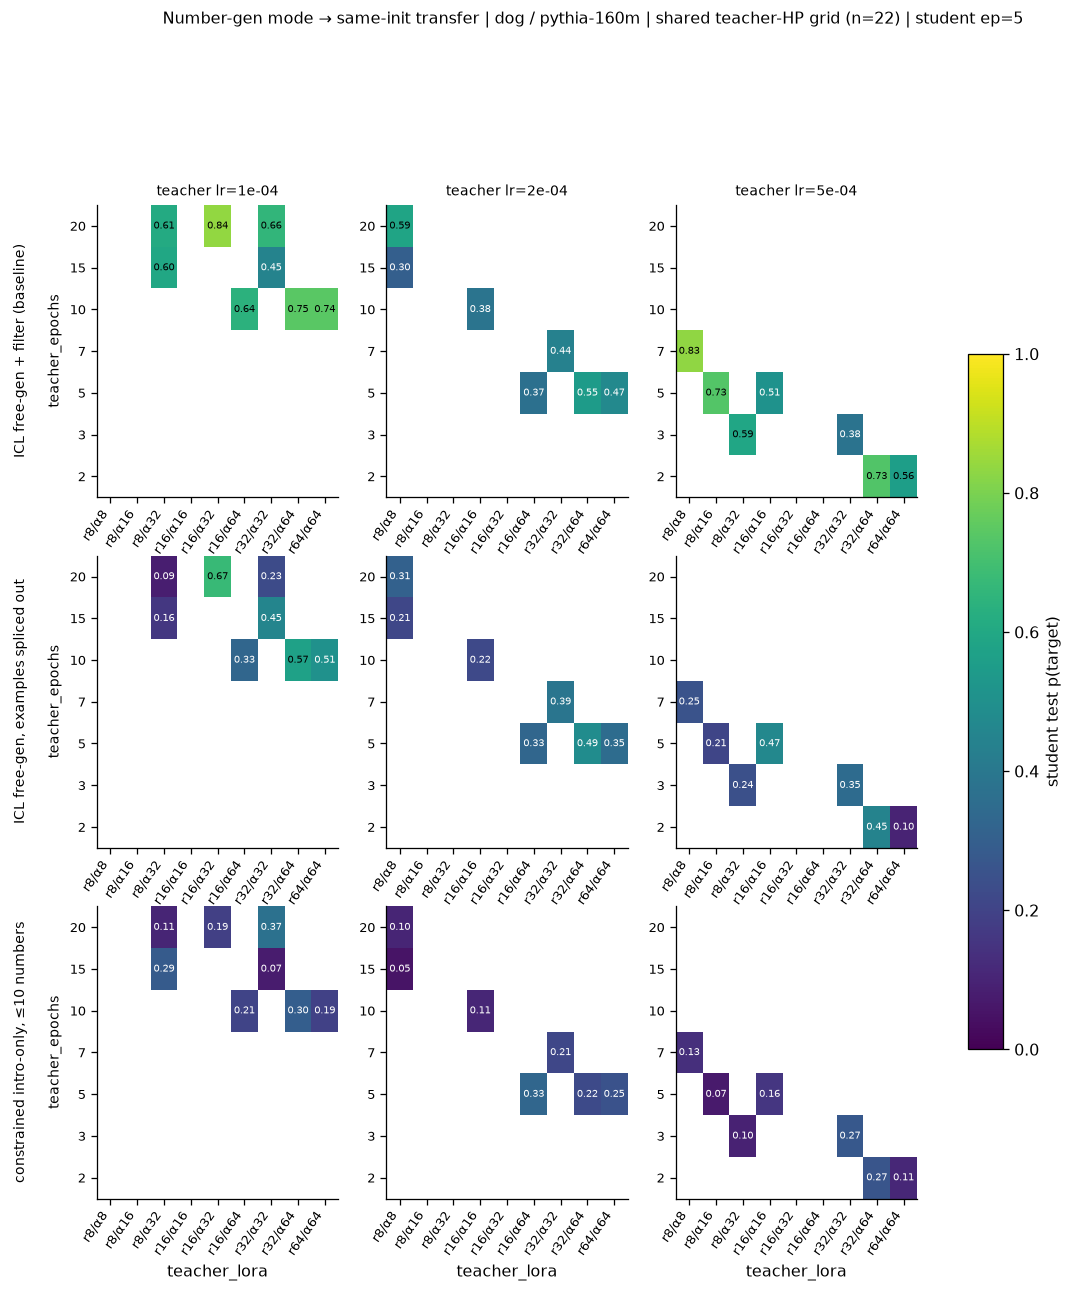

In [10]:
# Section 3's 2D grid (teacher epochs × teacher LoRA, faceted by teacher lr), TILED by
# number-generation mode. Restricted to the teacher-HP support shared by ALL three modes
# (= the constrained intro-u10 grid), so every panel shows the SAME cells and only the
# generation mode changes. Student dose fixed at PRIMARY_STUDENT_EPOCH; metric = held-out
# test p(target), shared 0..1 colour scale so the three rows are directly comparable.
MODE_ORDER = [("ex10-20_prefix_n100k",         "ICL free-gen + filter (baseline)"),
              ("ex10-20_prefix_n100k_spliced", "ICL free-gen, examples spliced out"),
              ("intro-u10_prefix_n10k",        "constrained intro-only, ≤10 numbers")]
GRID_EP = PRIMARY_STUDENT_EPOCH
g = wide[wide.dataset.isin([m for m,_ in MODE_ORDER]) & wide.student_epochs.eq(GRID_EP)].copy()
# Shared support: teacher HP tags present in EVERY mode (so all three panels carry identical cells).
support = set.intersection(*[set(g.loc[g.dataset.eq(m),"teacher_tag"]) for m,_ in MODE_ORDER])
g = g[g.teacher_tag.isin(support)]
assert len(support), "no teacher HP is present in all three number-gen modes"
assert not g.duplicated(["dataset","teacher_epochs","teacher_lora","teacher_lr"]).any(), \
    "duplicate teacher-HP keys would pool multiple runs per heatmap cell"
loras = sorted(g.teacher_lora.unique(), key=lambda x:tuple(map(int,re.findall(r"\d+",x))))
MODE_LABELS = dict(MODE_ORDER)
_ = aplots.facet_grid_heatmaps(
    g, row="teacher_epochs", col="teacher_lora", val="student_test",
    row_facet="dataset", col_facet="teacher_lr",
    orders={"dataset": [m for m,_ in MODE_ORDER], "teacher_lora": loras},
    mid=0.55, cmap="viridis", vmin=0, vmax=1, cbar_label="student test p(target)",
    row_facet_label=lambda m: MODE_LABELS[m],
    col_facet_label=lambda lr: f"teacher lr={lr:.0e}",
    title=f"Number-gen mode → same-init transfer | {SAME_INIT_ANIMAL} / {SAME_INIT_MODEL} | "
          f"shared teacher-HP grid (n={len(support)}) | student ep={GRID_EP}")

# Paired mode contrast on the shared grid. `spliced` trains on the SAME subsampled rows as the
# baseline (only the prompt prefix — the in-context examples — is removed), so its Δ is a clean
# paired effect. `intro-u10` is a DIFFERENT data-generating process (constrained decoding on its own
# pool); read its Δ as descriptive, not an apples-to-apples ablation (see the config-file caveat).
piv  = g.pivot_table(index="teacher_tag", columns="dataset", values="student_test")
base = MODE_ORDER[0][0]
summary = pd.DataFrame({"mean test p(target)":[piv[m].mean() for m,_ in MODE_ORDER],
                        "Δ vs baseline (paired)":[(piv[m]-piv[base]).mean() for m,_ in MODE_ORDER],
                        "n configs":[int(piv[m].notna().sum()) for m,_ in MODE_ORDER]},
                       index=[lbl for _,lbl in MODE_ORDER])
display(summary.style.format({"mean test p(target)":"{:.3f}","Δ vs baseline (paired)":"{:+.3f}"})
        .set_caption(f"Number-gen mode on the shared teacher-HP grid ({SAME_INIT_ANIMAL}/{SAME_INIT_MODEL}, student ep={GRID_EP})"))
print("Holding the teacher and student fixed, removing the in-context examples (spliced) and constraining "
      "decoding (intro-u10) each WEAKEN same-init transfer on the matched grid:")
print("  baseline {:.3f}  >  spliced {:.3f}  >  constrained {:.3f}   mean held-out test p(target).".format(
      *[piv[m].mean() for m,_ in MODE_ORDER]))

## 7. Cross-animal comparison — same-init transfer on one matched footing ⭐

Sections 1–4 profile **dog**; §5/§5b vary the base checkpoint and put three experiments side by
side. This section instead **holds every mechanical knob fixed and varies only the target animal**,
so subliminal-transfer strength is directly comparable across animals.

**Matched footing:** original `pythia-160m` base · the **100k `prefix` number pool** · teacher/ft
seed 1 · student seed 1 · **plain** prompts · student epochs {1, 2, 5, 10}. The animals sharing this
footing are **dog, lion, pig, rabbit** — each distils only from its own teachers' numbers over its
own qualifying HP set, so the per-animal *n* differs (printed below). `cat` is **not** here: its
original-base teachers used the 40k-era pool, so it lives in §5/§5b, not on this 100k footing.

Read the three panels as **(A)** how fast the trait transfers with student epochs (mean over each
animal's distillable configs), **(B)** the per-config spread at the primary epoch (teacher HP
matters — some configs transfer far more than others), and **(C)** out-of-distribution
storytelling leakage.

near-matched footing: pythia-160m · plain prefix · teacher-seed 1 · student-seed 1 · student recipe lr=0.0001 r8/α32
number pool per animal (⚠ not identical — see the cell header):


,pool
animal,
cat,prefix (40k pool)
dog,prefix (100k pool)
lion,prefix (100k pool)
pig,prefix (100k pool)
rabbit,prefix (100k pool)


animals: ['cat', 'dog', 'lion', 'pig', 'rabbit'] | configs per animal × student-epoch:


student_epochs,1,2,5,10,20
animal,,,,,
cat,84,84,84,84,0
dog,102,102,102,102,102
lion,96,96,96,96,0
pig,96,96,96,96,0
rabbit,92,92,92,92,0



Held-out `test` p_target and storytelling OOD by animal × student-epoch:


,animal,student_epochs,n,test_mean,test_median,test_max,story_mean
0,cat,1,84,0.028,0.016,0.131,0.046
1,cat,2,84,0.058,0.028,0.397,0.086
2,cat,5,84,0.117,0.052,0.712,0.135
3,cat,10,84,0.147,0.059,0.642,0.141
4,dog,1,102,0.081,0.048,0.336,0.104
5,dog,2,102,0.130,0.064,0.548,0.158
6,dog,5,102,0.228,0.145,0.838,0.220
7,dog,10,102,0.286,0.185,0.920,0.233
8,dog,20,102,0.298,0.243,0.968,0.180
9,lion,1,96,0.073,0.058,0.359,0.090


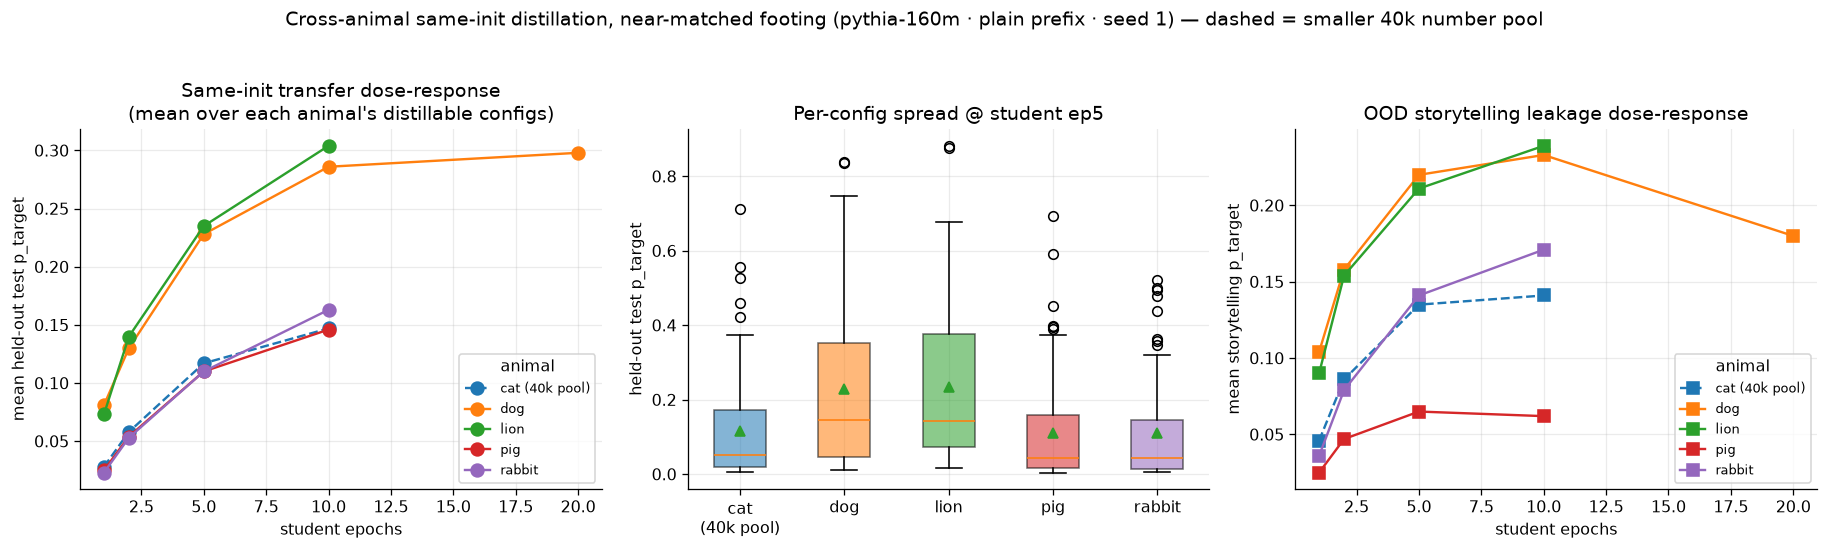

In [11]:
# Cross-animal same-init transfer on a near-matched footing: original pythia-160m base, plain
# prefix numbers, teacher/ft-seed 1, student-seed 1. Base, prompt template, teacher-HP grid, dose
# and student recipe are all held fixed, so the target animal is the main thing varying.
#
# ⚠ POOL CAVEAT — `cat` is included here despite a smaller candidate pool. Its original-base
# teachers predate the 100k pool, so cat's numbers were drawn from the 40k pool while every other
# animal uses 100k. Both train 10 000 rows, so the *dose* matches; what differs is the candidate
# pool the teacher's numbers were sampled from. Pool is therefore CONFOUNDED with animal for cat
# alone — read cat's level against the others with that in mind (see §5/§5b, where the same base
# is compared across pools). Set XDATASETS to just the 100k entry to drop cat again.
XMODEL, XT_SEED, XS_SEED = "pythia-160m", 1, 1
XDATASETS = ["ex10-20_prefix_n100k", "ex10-20_prefix_n40k"]  # n40k is cat-only here
XPOOL_CAVEAT = {"cat": "40k pool"}
# Student recipe pinned here too: without it the per-(animal x student_epochs) means below would
# silently average several student-HP recipes at ep20 (dog has 4 in-tree), breaking "matched footing".
xa = treatments_all[treatments_all.same_init.eq(True) & treatments_all.model.eq(XMODEL) &
                    treatments_all.dataset.isin(XDATASETS) & treatments_all.teacher_seed.eq(XT_SEED) &
                    treatments_all.student_seeds.map(lambda s: s == (XS_SEED,)) &
                    treatments_all.student_lr.eq(STUDENT_LR) & treatments_all.student_rank.eq(STUDENT_RANK) &
                    treatments_all.student_alpha.eq(STUDENT_ALPHA)].copy()
XMETA = ["config_id", "animal", "dataset", "teacher_tag", "student_epochs"]
xwide = xa.drop_duplicates("config_id")[XMETA].set_index("config_id")
xwide = xwide.join(xa.pivot(index="config_id", columns="set", values="p").add_prefix("student_")).reset_index()
for _s in ("test", "storytelling"):
    if f"student_{_s}" not in xwide: xwide[f"student_{_s}"] = np.nan
xanimals = sorted(xwide.animal.unique())
ACOLOR = dict(zip(xanimals, plt.cm.tab10.colors))
assert len(xwide), "cross-animal matched-footing slice is empty"
print(f"near-matched footing: {XMODEL} · plain prefix · teacher-seed {XT_SEED} · "
      f"student-seed {XS_SEED} · student recipe lr={STUDENT_LR:g} r{STUDENT_RANK}/α{STUDENT_ALPHA}")
_pools = xwide.groupby("animal").dataset.unique().apply(lambda v: ", ".join(LABEL.get(x, x) for x in v))
print("number pool per animal (⚠ not identical — see the cell header):")
display(_pools.rename("pool").to_frame())
print("animals:", xanimals, "| configs per animal × student-epoch:")
display(pd.crosstab(xwide.animal, xwide.student_epochs))

# Per-(animal × student-epoch) summary of held-out `test` transfer (+ storytelling OOD mean).
_g = (xwide.groupby(["animal", "student_epochs"])
      .agg(n=("student_test", "size"), test_mean=("student_test", "mean"),
           test_median=("student_test", "median"), test_max=("student_test", "max"),
           story_mean=("student_storytelling", "mean")).round(3).reset_index())
print("\nHeld-out `test` p_target and storytelling OOD by animal × student-epoch:")
display(_g)

EPS = sorted(xwide.student_epochs.unique())
PRIMARY_EP = 5 if 5 in EPS else EPS[-1]
fig, axs = plt.subplots(1, 3, figsize=(16, 4.6))
# (A) dose-response: mean held-out test transfer vs student epochs, one line per animal.
for a in xanimals:
    s = _g[_g.animal == a]
    _lab = f"{a} ({XPOOL_CAVEAT[a]})" if a in XPOOL_CAVEAT else a
    axs[0].plot(s.student_epochs, s.test_mean, marker="o", ms=8, color=ACOLOR[a],
                ls="--" if a in XPOOL_CAVEAT else "-", label=_lab)
axs[0].set(xlabel="student epochs", ylabel="mean held-out test p_target",
           title="Same-init transfer dose-response\n(mean over each animal's distillable configs)")
axs[0].legend(fontsize=8, title="animal")
# (B) distribution across configs at the primary student epoch.
data = [xwide[(xwide.animal == a) & (xwide.student_epochs == PRIMARY_EP)].student_test.dropna().values
        for a in xanimals]
bp = axs[1].boxplot(data, showmeans=True, patch_artist=True)
for patch, a in zip(bp["boxes"], xanimals): patch.set_facecolor(ACOLOR[a]); patch.set_alpha(.55)
axs[1].set_xticks(range(1, len(xanimals) + 1))
axs[1].set_xticklabels([f"{a}\n({XPOOL_CAVEAT[a]})" if a in XPOOL_CAVEAT else a for a in xanimals])
axs[1].set(ylabel="held-out test p_target", title=f"Per-config spread @ student ep{PRIMARY_EP}")
# (C) storytelling OOD dose-response, one line per animal.
for a in xanimals:
    s = _g[_g.animal == a]
    _lab = f"{a} ({XPOOL_CAVEAT[a]})" if a in XPOOL_CAVEAT else a
    axs[2].plot(s.student_epochs, s.story_mean, marker="s", ms=8, color=ACOLOR[a],
                ls="--" if a in XPOOL_CAVEAT else "-", label=_lab)
axs[2].set(xlabel="student epochs", ylabel="mean storytelling p_target",
           title="OOD storytelling leakage dose-response")
axs[2].legend(fontsize=8, title="animal")
fig.suptitle("Cross-animal same-init distillation, near-matched footing "
             "(pythia-160m · plain prefix · seed 1) — dashed = smaller 40k number pool",
             y=1.03, fontsize=12)
plt.tight_layout(); plt.show()

## 8. Teacher-HP surfaces per animal at one dose (`cat` vs `dog` vs the rest) ⭐

§7 compares animals as distributions; this section shows the **teacher hyperparameter surface itself**,
one heatmap grid per animal, so you can see *which* teacher cells transfer rather than only how much.
Scope: same-init `pythia-160m`, plain prefix numbers, teacher/ft-seed 1, student-seed 1, the pinned
student recipe, and a **single student dose (ep10)** — change `XA_DOSE` to re-render at ep1/2/5.

Five animals qualify: `cat`, `dog`, `lion`, `pig`, `rabbit`. **`cat` uses the 40k number pool** while
the others use 100k (both train 10 000 rows), so pool is confounded with animal for cat — the same
caveat as §7. Panels share a 0–1 colour scale, and the final scatter pairs `cat` against `dog` on
their shared teacher-HP cells.


same-init pythia-160m · plain prefix · student dose ep10 · teacher-seed 1 · student-seed 1 · student recipe lr=0.0001 r8/α32
pool per animal: {'cat': 'ex10-20_prefix_n40k', 'dog': 'ex10-20_prefix_n100k', 'lion': 'ex10-20_prefix_n100k', 'pig': 'ex10-20_prefix_n100k', 'rabbit': 'ex10-20_prefix_n100k'}


teacher_lr,0.000010,0.000100,0.000200,0.000500,0.001000
animal,,,,,
cat,0,31,27,16,10
dog,2,37,28,23,12
lion,0,35,30,21,10
pig,0,34,31,20,11
rabbit,0,33,29,20,10


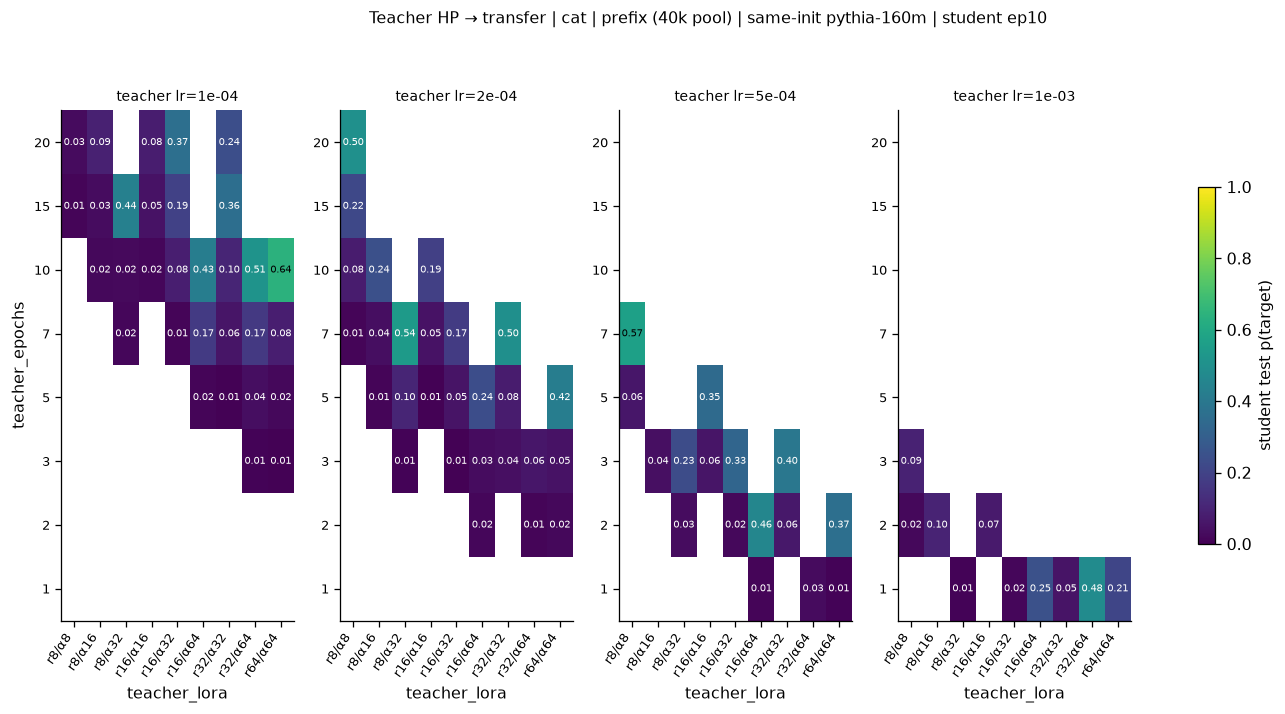

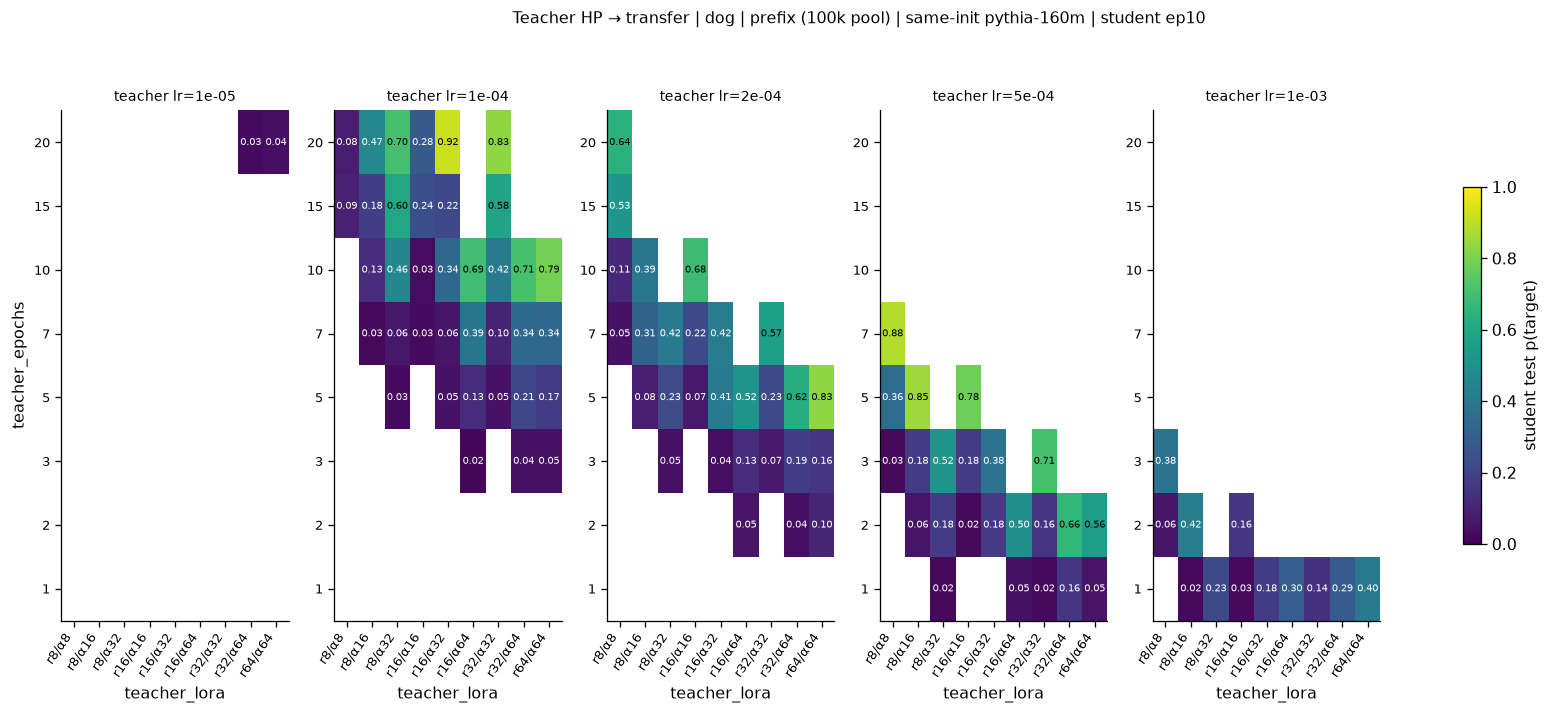

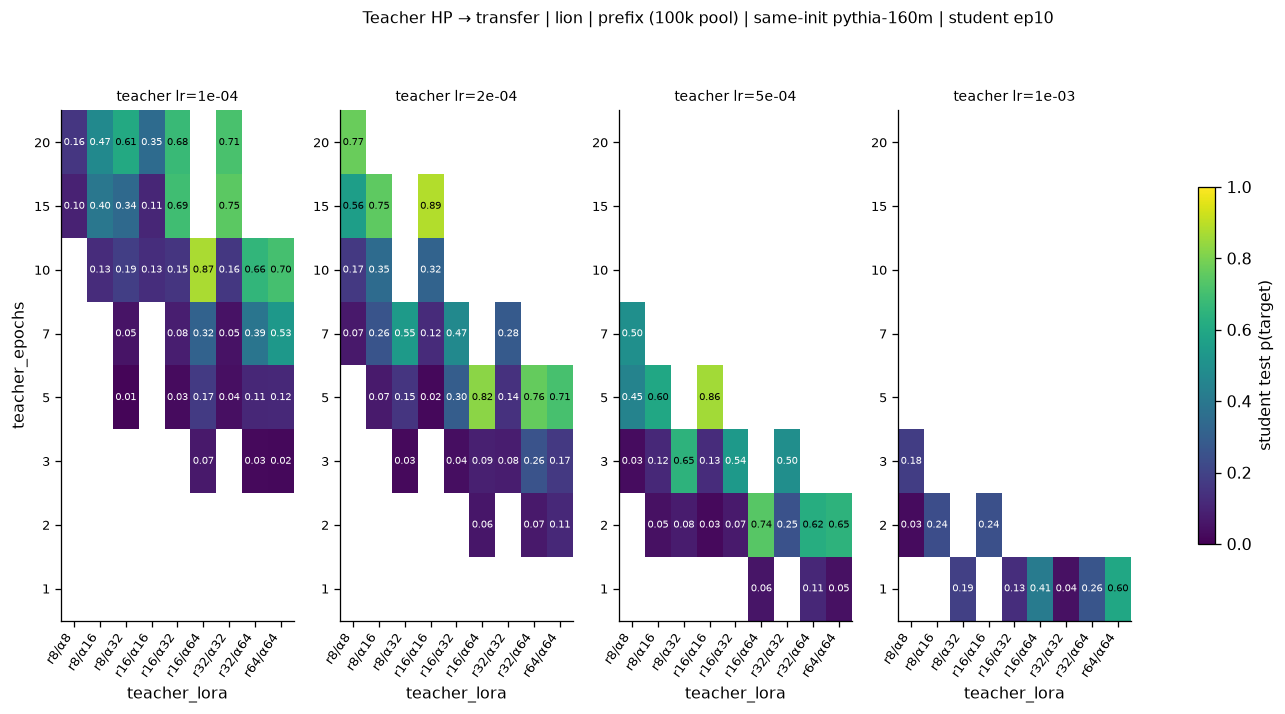

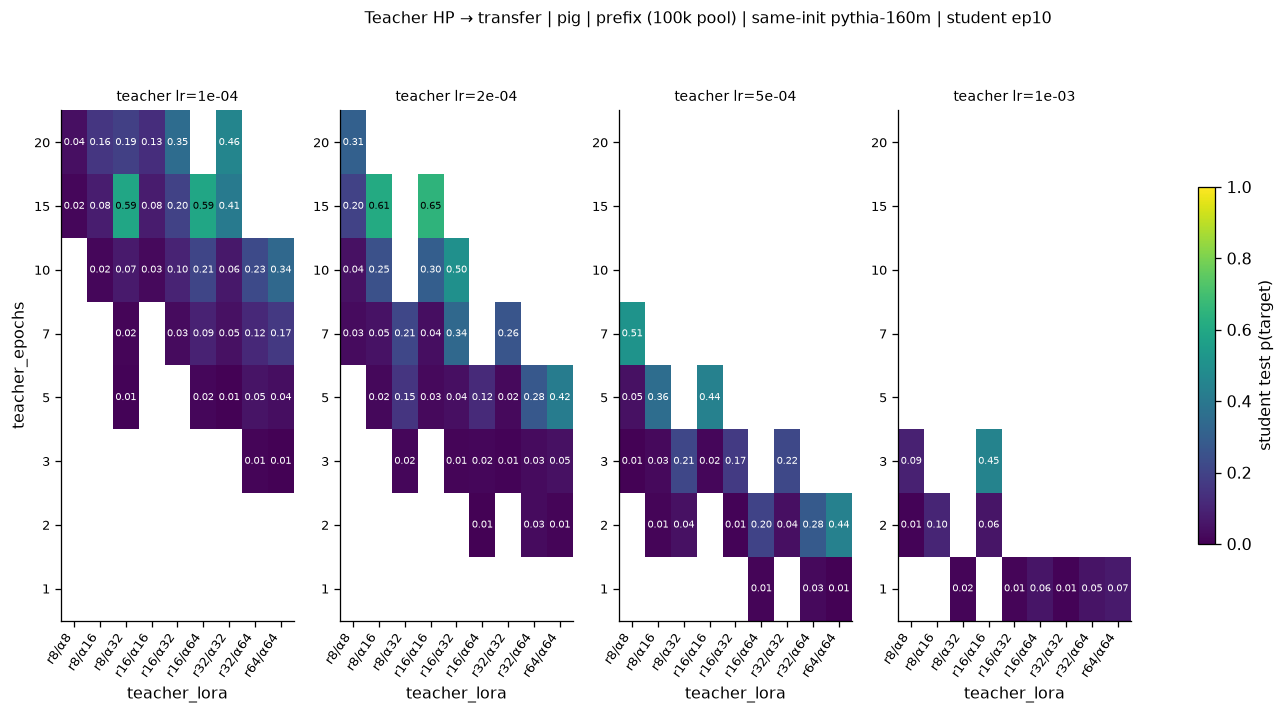

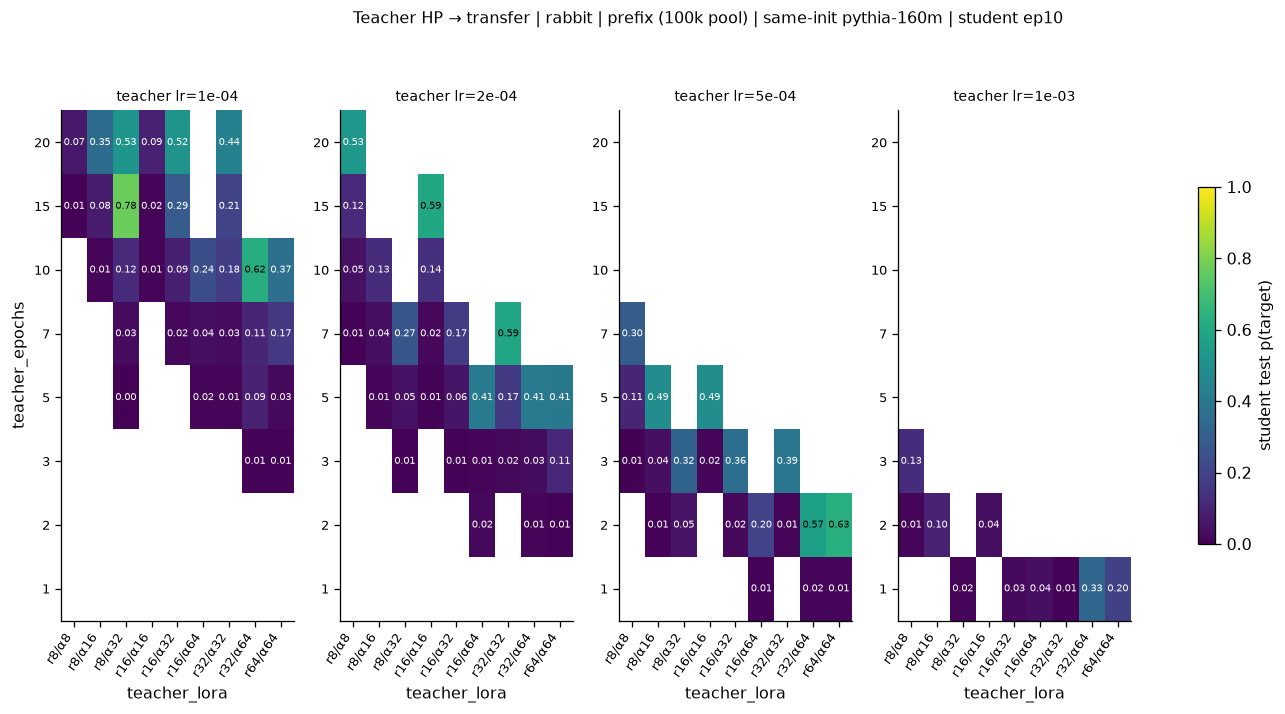

,n,mean,median,q90,max
animal,,,,,
cat,84,0.147000,0.059000,0.433000,0.642000
dog,102,0.286000,0.185000,0.692000,0.920000
lion,96,0.304000,0.184000,0.712000,0.885000
pig,96,0.146000,0.058000,0.429000,0.650000
rabbit,92,0.163000,0.063000,0.490000,0.776000


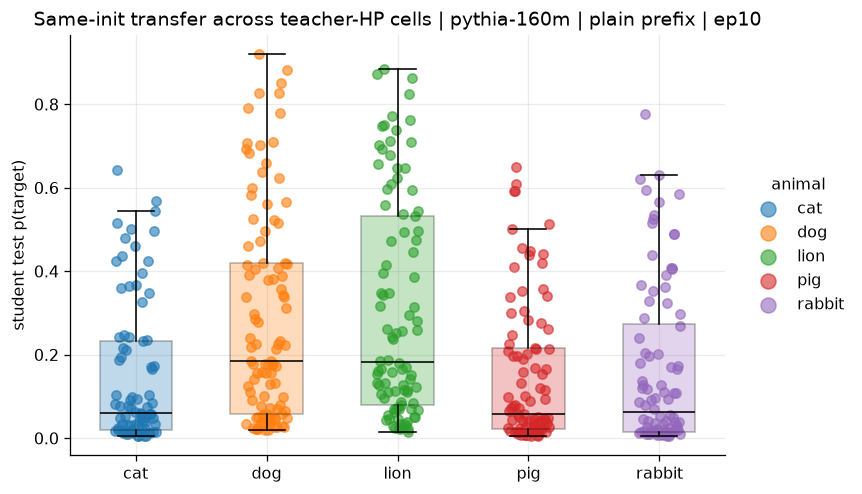

cat vs dog @ ep10: 84 shared teacher-HP cells (cat pool n40k vs dog pool n100k — pool is confounded with animal here)


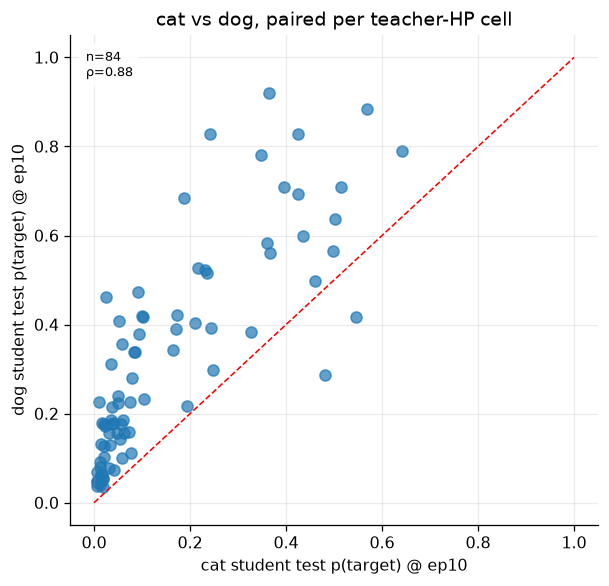

In [12]:
# Cross-animal teacher-HP surfaces on the same-init `pythia-160m` base, plain prefix numbers,
# at a single student dose (ep10 — every animal here has it; dog alone also has ep20).
# One heatmap per animal on a shared 0-1 colour scale so panels are directly comparable:
# rows = teacher epochs, cols = teacher LoRA, facet cols = teacher LR. The student recipe is
# pinned (STUDENT_LR/RANK/ALPHA), so within a panel the teacher HP is the only thing varying.
XA_MODEL, XA_TSEED, XA_SSEED = "pythia-160m", 1, 1
XA_DOSE = 10                       # set to another dose (1/2/5) to re-render; 20 is dog-only

# Plain prefix pools only: cat's original-base teachers predate the 100k pool, so cat is n40k and
# the rest are n100k. Both pools train 10 000 rows; the pool only changes which candidates the
# teacher's numbers were drawn from — so pool is CONFOUNDED with animal in any cat-vs-rest read.
xa8 = treatments_all[
    treatments_all.same_init.eq(True)
    & treatments_all.model.eq(XA_MODEL)
    & treatments_all.teacher_seed.eq(XA_TSEED)
    & treatments_all.student_seeds.map(lambda s: s == (XA_SSEED,))
    & treatments_all.student_lr.eq(STUDENT_LR)
    & treatments_all.student_rank.eq(STUDENT_RANK)
    & treatments_all.student_alpha.eq(STUDENT_ALPHA)
    & treatments_all.dataset.isin(["ex10-20_prefix_n40k", "ex10-20_prefix_n100k"])
    & treatments_all.student_epochs.eq(XA_DOSE)
].copy()
assert len(xa8), f"cross-animal same-init prefix slice is empty at ep{XA_DOSE}"

XA_META = ["config_id", "animal", "dataset", "teacher_tag", "teacher_epochs", "teacher_lr",
           "teacher_rank", "teacher_alpha", "student_epochs"]
xa8w = xa8.drop_duplicates("config_id")[XA_META].set_index("config_id")
xa8w = xa8w.join(xa8.pivot(index="config_id", columns="set", values="p").add_prefix("student_")).reset_index()
if "student_test" not in xa8w: xa8w["student_test"] = np.nan
xa8w["teacher_lora"] = xa8w.apply(lambda x: f"r{x.teacher_rank}/α{x.teacher_alpha}", axis=1)

# Same one-run-per-cell invariant the section-3 grid needs, now per animal.
XA_DUP = ["animal", "teacher_epochs", "teacher_lora", "teacher_lr"]
assert not xa8w.duplicated(XA_DUP).any(), \
    f"duplicate teacher-HP keys: {xa8w[xa8w.duplicated(XA_DUP, keep=False)][XA_DUP].to_dict('records')}"

xa8_animals = sorted(xa8w.animal.unique())
print(f"same-init {XA_MODEL} · plain prefix · student dose ep{XA_DOSE} · teacher-seed {XA_TSEED} · "
      f"student-seed {XA_SSEED} · student recipe lr={STUDENT_LR:g} r{STUDENT_RANK}/α{STUDENT_ALPHA}")
print("pool per animal:", xa8w.groupby("animal").dataset.unique().apply(lambda v: ", ".join(v)).to_dict())
display(pd.crosstab(xa8w.animal, xa8w.teacher_lr).style.set_caption(
    f"Teacher-HP cells per animal × teacher LR at ep{XA_DOSE} (one run per cell)"))

# --- per-animal teacher-HP surfaces (per-animal view first, cross-animal summary after) --------
xa8_loras = sorted(xa8w.teacher_lora.unique(), key=lambda x: tuple(map(int, re.findall(r"\d+", x))))
for animal in xa8_animals:
    ha = xa8w[xa8w.animal.eq(animal)]
    pool = LABEL.get(ha.dataset.iloc[0], ha.dataset.iloc[0])
    _ = aplots.facet_grid_heatmaps(
        ha, row="teacher_epochs", col="teacher_lora", val="student_test",
        col_facet="teacher_lr",
        orders={"teacher_lora": xa8_loras}, mid=0.55, cmap="viridis", vmin=0, vmax=1,
        cbar_label="student test p(target)",
        col_facet_label=lambda lr: f"teacher lr={lr:.0e}",
        title=f"Teacher HP → transfer | {animal} | {pool} | same-init {XA_MODEL} | student ep{XA_DOSE}")
    plt.show()

# --- cross-animal summary at this dose (aggregation named on the table) ------------------------
xa8_summary = (xa8w.groupby("animal")
               .agg(n=("student_test", "size"), mean=("student_test", "mean"),
                    median=("student_test", "median"), q90=("student_test", lambda s: s.quantile(.9)),
                    max=("student_test", "max"))
               .round(3))
display(xa8_summary.style.set_caption(
    f"Held-out `test` p(target) at ep{XA_DOSE}, MEAN/MEDIAN OVER TEACHER-HP CELLS (not over seeds)"))

fig, ax = plt.subplots(figsize=(7.6, 4.4))
data = [xa8w.loc[xa8w.animal.eq(a), "student_test"].dropna().values for a in xa8_animals]
bp = ax.boxplot(data, positions=range(len(xa8_animals)), widths=.55, patch_artist=True,
                showfliers=False, medianprops={"color": "black"})
for patch, a in zip(bp["boxes"], xa8_animals):
    patch.set_facecolor(plt.cm.tab10.colors[xa8_animals.index(a)]); patch.set_alpha(.28)
for i, a in enumerate(xa8_animals):
    v = xa8w.loc[xa8w.animal.eq(a), "student_test"].dropna().values
    jitter = np.linspace(-.16, .16, len(v)) if len(v) > 1 else [0]
    ax.scatter(i + jitter, v, s=34, alpha=.6, color=plt.cm.tab10.colors[i], label=a)
ax.set_xticks(range(len(xa8_animals))); ax.set_xticklabels(xa8_animals)
ax.set_ylabel("student test p(target)")
ax.set_title(f"Same-init transfer across teacher-HP cells | {XA_MODEL} | plain prefix | ep{XA_DOSE}")
ax.legend(title="animal", loc="center left", bbox_to_anchor=(1.02, .5), frameon=False, markerscale=1.6)
fig.tight_layout(); plt.show()

# --- cat vs dog, paired on the shared teacher-HP grid ------------------------------------------
PAIR_KEYS = ["teacher_epochs", "teacher_lora", "teacher_lr"]
cd = {a: xa8w[xa8w.animal.eq(a)].set_index(PAIR_KEYS) for a in ("cat", "dog") if a in xa8_animals}
if len(cd) == 2:
    shared = cd["cat"].index.intersection(cd["dog"].index)
    print(f"cat vs dog @ ep{XA_DOSE}: {len(shared)} shared teacher-HP cells "
          f"(cat pool n40k vs dog pool n100k — pool is confounded with animal here)")
    if len(shared):
        fig, ax = plt.subplots(figsize=(5.4, 5.2))
        aplots.identity_scatter(
            ax, pd.DataFrame({"cat": cd["cat"].loc[shared, "student_test"],
                              "dog": cd["dog"].loc[shared, "student_test"]}),
            x="cat", y="dog", s=48, alpha=.7, stat="spearman", textbox=True)
        ax.set_xlabel(f"cat student test p(target) @ ep{XA_DOSE}")
        ax.set_ylabel(f"dog student test p(target) @ ep{XA_DOSE}")
        ax.set_title("cat vs dog, paired per teacher-HP cell")
        fig.tight_layout(); plt.show()
else:
    print("cat and/or dog missing from the slice — paired panel skipped")


## 9. Teacher ranking by animal — does dog's teacher ordering carry to cat/lion/pig/rabbit? ⭐

§8 shows each animal's teacher-HP *surface*; this section turns each surface into an explicit **ranking of
teachers** and asks how far dog's ordering is an animal-specific artefact.

**Matched footing (identical to §7/§8, stated again because the ranking is only as comparable as its basis).**
Row unit = one **teacher HP set** (`{tag}_tseed1`) on the same-init `pythia-160m` base, plain `prefix`
numbers, student seed 1, student recipe pinned to `lr 1e-4 / r8 / α32`. A teacher's score is the **max over
the four shared student doses** `ep{1,2,5,10}` of that cell's ft-seed mean — the same 4-cell menu for every
animal, so no animal gets extra lottery tickets. Dog's own `ep20` and top-3 recipes are **excluded here** for
exactly that reason (they exist only for dog); dog's unrestricted numbers are higher and appear in §1–§4.

**⚠ `cat` is on the 40k pool**, every other animal on 100k (both train 10 000 rows) — the same confound §7/§8
carry. Cat also has 84 teachers to dog's 102, so its ranks are drawn from a smaller set.

Two tables:

1. **Ranking side by side** — top 30 teachers per animal, each shown as `teacher tag (score)`. **Bold** marks
   a teacher that is in **dog's top 20**. Column-wise reading only: rank *k* in one column and rank *k* in
   another are different teachers.
2. **Dog's top 20, resolved into every animal's ranking** — one row per dog-top-20 teacher, columns give that
   teacher's rank and score under each animal (`—` = that teacher was never trained for that animal).
   This is the direct answer to "does dog's best set transfer": read the rank columns.

The footer prints, per animal, how many of dog's top 20 land in that animal's top 30, and the Spearman rank
correlation of teacher scores against dog over all teachers the two animals share.


In [13]:
# §9 is self-contained: runnable from a fresh kernel without the §1 loaders. It rescans the
# same-init student tree directly so the "matched footing" is enforced here rather than inherited.
# Basis: same-init base pythia-160m, plain prefix pool, tseed1, student recipe lr1e-4/r8/a32, and the
# FOUR shared student doses ep{1,2,5,10}. A teacher's score = max over those four cells of the ft-seed
# mean. Dog's extra ep20/top-3 recipes are deliberately excluded -- only dog has them, and including
# them would give dog a bigger menu to maximise over than any other animal.
import re
import numpy as np
import pandas as pd
from IPython.display import display

from subliminal_learning.analysis.frames import load_cell_summaries, summary_set_block
from subliminal_learning.analysis.setup import bootstrap

ROOT9, OUT9 = bootstrap()
SAME_BASE9 = "pythia-160m"                                   # same-init: student base == teacher base
POOLS9 = {"ex10-20_prefix_n100k": "100k", "ex10-20_prefix_n40k": "40k"}   # n40k is cat-only
STD_CELLS9 = ["ep1_lr1e-4_r8a32", "ep2_lr1e-4_r8a32", "ep5_lr1e-4_r8a32", "ep10_lr1e-4_r8a32"]
TSEED9, TOP_N9, DOG_TOP9 = "tseed1", 30, 20
ANIMAL_ORDER9 = ["dog", "cat", "lion", "pig", "rabbit"]


def _scan9() -> pd.DataFrame:
    # Discovery unchanged; the per-cell summaries are read in one batched, cached sweep
    # (paths relative to OUT9, where the cache CSV lands).
    cells = []
    for adir in sorted((OUT9 / "students").iterdir()):
        if not adir.is_dir() or adir.name not in ANIMAL_ORDER9:
            continue
        troot = adir / SAME_BASE9 / f"teacher-{SAME_BASE9}"
        if not troot.exists():
            continue
        for tdir in sorted(troot.glob(f"*_{TSEED9}")):
            for ds, pool in POOLS9.items():
                lin = tdir / ds
                if not lin.exists():
                    continue
                for cell in STD_CELLS9:
                    cd = lin / cell
                    if not cd.is_dir():
                        continue
                    cells.append((adir.name, pool, tdir.name[: -len(f"_{TSEED9}")], cell, cd))
    rels = [str(cd.relative_to(OUT9)) for *_, cd in cells]
    docs = load_cell_summaries(OUT9, rels)
    rows = []
    for (animal, pool, teacher, cell, _), rel in zip(cells, rels):
        block = summary_set_block(docs.get(rel), "test")
        seeds = {int(s): float(v) for s, v in ((block or {}).get("per_seed_p_target") or {}).items()}
        if seeds:
            rows.append(dict(animal=animal, pool=pool, teacher=teacher, cell=cell,
                             cell_mean=float(np.mean(list(seeds.values()))),
                             n_seeds=len(seeds)))
    return pd.DataFrame(rows)

s9 = _scan9()
ANIMALS9 = [a for a in ANIMAL_ORDER9 if a in set(s9.animal)]
# teacher score = max over the four shared doses; keep which dose won and how many were present.
rank9 = (s9.sort_values("cell_mean", ascending=False)
         .groupby(["animal", "teacher"], as_index=False)
         .agg(score=("cell_mean", "max"), best_dose=("cell", "first"),
              n_cells=("cell", "size"), pool=("pool", "first")))
rank9["rank"] = rank9.groupby("animal").score.rank(ascending=False, method="first").astype(int)
DOG_TOP20 = set(rank9[(rank9.animal == "dog") & (rank9["rank"] <= DOG_TOP9)].teacher)

print(f"same-init {SAME_BASE9} · plain prefix · {TSEED9} · student recipe lr1e-4/r8/α32 · "
      f"score = max over doses {', '.join(c.split('_')[0] for c in STD_CELLS9)}")
display(rank9.groupby("animal").agg(teachers=("teacher", "nunique"), pool=("pool", "first"),
                                    doses_per_teacher=("n_cells", "median"),
                                    best_score=("score", "max"), median_score=("score", "median"))
        .reindex(ANIMALS9).round(3)
        .style.set_caption("Ranking basis per animal — row unit = one animal; "
                           "`teachers` = teacher HP sets ranked (⚠ cat is on the 40k pool)"))

# --- Table 1: top-30 ranking side by side, bold = in dog's top 20 -------------------------------
side9 = pd.DataFrame({
    a: pd.Series([f"{t.replace('_tseed1', '')} ({v:.3f})"
                  for t, v in zip(g.teacher, g.score)])
    for a in ANIMALS9
    for g in [rank9[rank9.animal == a].sort_values("rank").head(TOP_N9)]})
side9.index = pd.RangeIndex(1, len(side9) + 1, name="rank")
bold9 = pd.DataFrame({
    a: pd.Series(["font-weight: bold" if t in DOG_TOP20 else "" for t in
                  rank9[rank9.animal == a].sort_values("rank").head(TOP_N9).teacher])
    for a in ANIMALS9}).set_axis(side9.index)
display(side9.fillna("").style.apply(lambda _: bold9.reindex_like(side9).fillna(""), axis=None)
        .set_caption(f"Top {TOP_N9} teachers per animal (read COLUMN-wise — rank k differs by column). "
                     f"Cell = teacher HP set (best-dose score). <b>Bold</b> = in dog's top {DOG_TOP9}."))

# --- Table 2: dog's top 20 resolved into every other animal's ranking ---------------------------
piv_r = rank9.pivot(index="teacher", columns="animal", values="rank")
piv_s = rank9.pivot(index="teacher", columns="animal", values="score")
dog20 = (piv_r.loc[sorted(DOG_TOP20, key=lambda t: piv_r.loc[t, "dog"])]
         .join(piv_s, rsuffix="_score"))
dog20 = dog20[[c for a in ANIMALS9 for c in (a, f"{a}_score")]]
dog20.columns = pd.MultiIndex.from_tuples([(c.replace("_score", ""),
                                            "score" if c.endswith("_score") else "rank")
                                           for c in dog20.columns])
dog20.index = [t.replace("_tseed1", "") for t in dog20.index]
dog20.index.name = "dog top-20 teacher"
display(dog20.style
        .format({c: ("{:.0f}" if c[1] == "rank" else "{:.3f}") for c in dog20.columns}, na_rep="—")
        .background_gradient(subset=[c for c in dog20.columns if c[1] == "rank"],
                             cmap="viridis_r", vmin=1, vmax=60)
        .set_caption(f"Dog's top {DOG_TOP9} teachers, resolved into each animal's own ranking "
                     "(rank 1 = that animal's best teacher; — = never trained for that animal). "
                     "Row unit = one teacher HP set; scores are the same max-over-4-doses quantity."))

# --- Footer: overlap and rank correlation vs dog ------------------------------------------------
agree = []
for a in ANIMALS9:
    if a == "dog":
        continue
    top30 = set(rank9[(rank9.animal == a) & (rank9["rank"] <= TOP_N9)].teacher)
    common = piv_s[["dog", a]].dropna()
    agree.append({"animal": a, "pool": rank9.loc[rank9.animal == a, "pool"].iloc[0],
                  "teachers": int(piv_s[a].notna().sum()),
                  f"dog top{DOG_TOP9} present at all": len(DOG_TOP20 & set(piv_s[a].dropna().index)),
                  f"dog top{DOG_TOP9} in its top{TOP_N9}": len(DOG_TOP20 & top30),
                  "n shared teachers": len(common),
                  "Spearman vs dog": round(common.dog.corr(common[a], method="spearman"), 3)})
display(pd.DataFrame(agree).style.hide(axis="index")
        .set_caption("Agreement with dog's ranking — row unit = one animal. Spearman is over ALL "
                     "teachers that animal shares with dog, not just the top 30."))


same-init pythia-160m · plain prefix · tseed1 · student recipe lr1e-4/r8/α32 · score = max over doses ep1, ep2, ep5, ep10


,teachers,pool,doses_per_teacher,best_score,median_score
animal,,,,,
dog,102,100k,4.000000,0.920000,0.215000
cat,84,40k,4.000000,0.712000,0.064000
lion,96,100k,4.000000,0.885000,0.188000
pig,96,100k,4.000000,0.692000,0.061000
rabbit,92,100k,4.000000,0.776000,0.067000


,dog,cat,lion,pig,rabbit
rank,,,,,
1,ep20_lr1e-4_r16a32 (0.920),ep10_lr1e-4_r32a64 (0.712),ep15_lr2e-4_r16a16 (0.885),ep20_lr1e-4_r32a32 (0.692),ep15_lr1e-4_r8a32 (0.776)
2,ep7_lr5e-4_r8a8 (0.883),ep10_lr1e-4_r64a64 (0.642),ep15_lr2e-4_r8a16 (0.875),ep15_lr2e-4_r16a16 (0.650),ep2_lr5e-4_r64a64 (0.630)
3,ep5_lr5e-4_r8a16 (0.852),ep7_lr5e-4_r8a8 (0.569),ep10_lr1e-4_r16a64 (0.872),ep15_lr2e-4_r8a16 (0.610),ep10_lr1e-4_r32a64 (0.622)
4,ep5_lr2e-4_r64a64 (0.828),ep5_lr2e-4_r64a64 (0.556),ep5_lr5e-4_r16a16 (0.862),ep15_lr1e-4_r16a64 (0.593),ep15_lr2e-4_r16a16 (0.594)
5,ep20_lr1e-4_r32a32 (0.828),ep7_lr2e-4_r8a32 (0.545),ep5_lr2e-4_r16a64 (0.824),ep15_lr1e-4_r8a32 (0.592),ep7_lr2e-4_r32a32 (0.586)
6,ep10_lr1e-4_r64a64 (0.791),ep20_lr2e-4_r8a8 (0.502),ep20_lr2e-4_r8a8 (0.771),ep7_lr5e-4_r8a8 (0.514),ep2_lr5e-4_r32a64 (0.567)
7,ep5_lr5e-4_r16a16 (0.780),ep7_lr2e-4_r32a32 (0.498),ep5_lr2e-4_r32a64 (0.763),ep10_lr2e-4_r16a32 (0.500),ep20_lr2e-4_r8a8 (0.534)
8,ep10_lr1e-4_r32a64 (0.746),ep1_lr1e-3_r32a64 (0.481),ep15_lr1e-4_r32a32 (0.748),ep3_lr1e-3_r16a16 (0.448),ep20_lr1e-4_r8a32 (0.525)
9,ep2_lr5e-4_r32a64 (0.727),ep2_lr5e-4_r16a64 (0.461),ep2_lr5e-4_r16a64 (0.738),ep5_lr5e-4_r16a16 (0.441),ep20_lr1e-4_r16a32 (0.516)


animal,pool,teachers,dog top20 present at all,dog top20 in its top30,n shared teachers,Spearman vs dog
cat,40k,84,16,16,84,0.914000
lion,100k,96,20,18,94,0.925000
pig,100k,96,20,20,91,0.924000
rabbit,100k,92,20,19,91,0.928000


## 10. SGD vs AdamW — the optimizer arm ⭐

Same-init dog students, everything mechanical matched (base `pythia-160m`, teachers `tseed1`,
plain 100k prefix pool, student r8/α32, single `ftseed1`), varying only the optimizer and — in
§10.1 — the SGD learning rate. Readout throughout: held-out `test`/`prob` mean p_target over
50 prompts; dashed reference is the matched base-numbers control (same recipe, no teacher signal).

- **§10.0** top-5 dog teachers, AdamW vs SGD at the matched recipe ep10/lr1e-4.
- **§10.1** `sgd-stage0-lr-bracket` ladder: 2 teachers × 9 SGD lrs (1e-4 … 1e0).
- **§10.2** Pile integrity: KL(base‖student) + ΔCE on the pp1 pool for all 21 SGD students
  (`{run_dir}/eval/pile_probe.json`, probed 2026-08-20).


row = one top-5 dog teacher (rank order frozen); values = test/prob mean p_target, student ep10_lr1e-4_r8a32, ftseed1.  base-numbers control floor = 0.0049


,teacher,adamw,sgd,sgd/adamw
0,ep20_lr1e-4_r16a32,0.9202,0.0101,0.0110
1,ep2_lr5e-4_r32a64,0.6603,0.0102,0.0155
2,ep7_lr5e-4_r8a8,0.8832,0.0103,0.0116
3,ep10_lr1e-4_r64a64,0.7907,0.0100,0.0126
4,ep20_lr1e-4_r8a16,0.4723,0.0099,0.0210


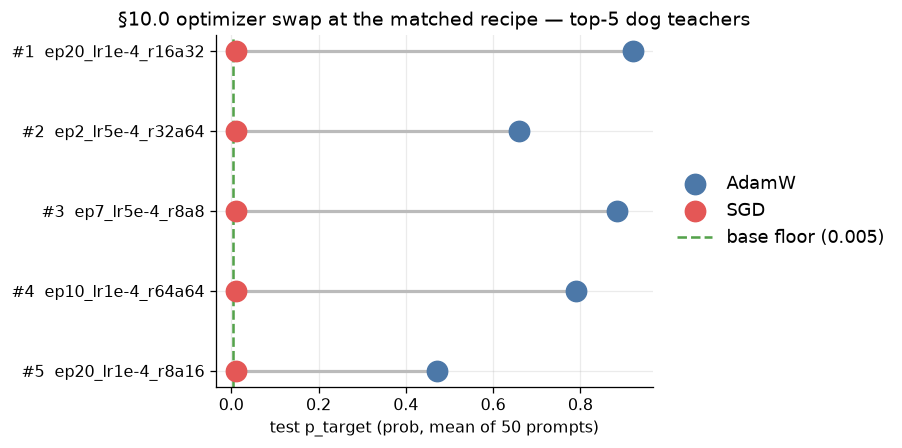

In [1]:
# §10.0 — top-5 screen, AdamW vs SGD at the matched recipe. Self-contained: rescans the tree.
import json, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from subliminal_learning.analysis.frames import load_cell_summaries, read_json
from subliminal_learning.analysis.setup import bootstrap, set_plot_style

_, OUT10 = bootstrap()
set_plot_style(dpi=115, grid_alpha=0.25, hide_spines=True)
STUD10 = OUT10 / "students"
TDIR10 = "dog/pythia-160m/teacher-pythia-160m"
DATASET10 = "ex10-20_prefix_n100k"
LEAF10 = "ep10_lr1e-4_r8a32"  # matched AdamW recipe; SGD leaves live under students/sgd/ with `_sgd` suffix
# Frozen top-5 dog teachers by same-model AdamW transfer (dog_top20krungs_configs.json param_tags[:5]).
TOP5_10 = ["ep20_lr1e-4_r16a32", "ep2_lr5e-4_r32a64", "ep7_lr5e-4_r8a8",
           "ep10_lr1e-4_r64a64", "ep20_lr1e-4_r8a16"]


def _test_prob(doc: dict, where) -> float:
    """mean p_target, test/prob, 50 prompts; asserts the single-ftseed1 footing."""
    assert tuple(map(int, doc.get("ft_seeds", []))) == (1,), where
    (s,) = [s for s in doc["summaries"] if s["prompt_set"] == "test" and s.get("scoring") == "prob"]
    assert s["n_prompts"] == 50, where
    return s["p_target_mean"]


def _cell_docs10(dirs):
    """Batched preference_summary.json reads for cell dirs (rel to OUT10 — cache in its analysis/)."""
    rels = [str(Path(d).relative_to(OUT10)) for d in dirs]
    docs = load_cell_summaries(OUT10, rels)
    missing = [r for r in rels if r not in docs]
    assert not missing, f"no readable preference_summary.json: {missing}"
    return [docs[r] for r in rels]


def _leaf10(teacher: str, leaf: str, sgd: bool) -> Path:
    top = STUD10 / "sgd" if sgd else STUD10
    suffix = "_sgd" if sgd else ""
    return top / TDIR10 / f"{teacher}_tseed1" / DATASET10 / f"{leaf}{suffix}"


BASE_DIR10 = (STUD10 / "controls/base/pythia-160m/teacher-pythia-160m" /
              DATASET10 / LEAF10 / "eval/dog")
_dirs10 = [BASE_DIR10] + [_leaf10(t, LEAF10, sgd=sgd) for t in TOP5_10 for sgd in (False, True)]
_docs10 = _cell_docs10(_dirs10)

BASE_RATE10 = _test_prob(_docs10[0], BASE_DIR10)

tbl10 = pd.DataFrame([
    dict(teacher=t,
         adamw=_test_prob(_docs10[1 + 2 * i], _dirs10[1 + 2 * i]),
         sgd=_test_prob(_docs10[2 + 2 * i], _dirs10[2 + 2 * i]))
    for i, t in enumerate(TOP5_10)])
tbl10["sgd/adamw"] = tbl10.sgd / tbl10.adamw

print(f"row = one top-5 dog teacher (rank order frozen); values = test/prob mean p_target, "
      f"student {LEAF10}, ftseed1.  base-numbers control floor = {BASE_RATE10:.4f}")
display(tbl10.round(4))

fig, ax = plt.subplots(figsize=(8, 4))
y = np.arange(len(tbl10))[::-1]
ax.hlines(y, tbl10.sgd, tbl10.adamw, color="#bbbbbb", lw=2)
ax.scatter(tbl10.adamw, y, s=160, color="#4c78a8", label="AdamW", zorder=3)
ax.scatter(tbl10.sgd, y, s=160, color="#e45756", label="SGD", zorder=3)
ax.axvline(BASE_RATE10, ls="--", color="#54a24b", lw=1.6, label=f"base floor ({BASE_RATE10:.3f})")
ax.set_yticks(y, [f"#{i+1}  {t}" for i, t in enumerate(tbl10.teacher)])
ax.set_xlabel("test p_target (prob, mean of 50 prompts)")
ax.set_title("§10.0 optimizer swap at the matched recipe — top-5 dog teachers")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=11)
fig.tight_layout(); plt.show()


### 10.1 SGD lr ladder — is SGD dead, or just under-dosed at lr1e-4?

`sgd-stage0-lr-bracket` (drained 2026-08-14): teachers `ep20_lr1e-4_r8a16` and `ep7_lr5e-4_r8a8`
(top-5 ranks #5 and #3), SGD students at 9 lrs `1e-4 … 1e0` (recipe otherwise ep10/r8/α32,
ftseed1). Solid dots = SGD ladder; open square = the matched AdamW student at its recipe lr 1e-4.


row = one SGD student (ftseed1) at one lr; p_target = test/prob mean over 50 prompts


teacher,ep20_lr1e-4_r8a16,ep7_lr5e-4_r8a8
lr,,
0.0001,0.0099,0.0103
0.0003,0.0113,0.0120
0.0010,0.0168,0.0191
0.0030,0.0436,0.0632
0.0100,0.1498,0.2767
0.0300,0.2730,0.7514
0.1000,0.0028,0.0280
0.3000,0.0000,0.0004
1.0000,0.0000,0.0000


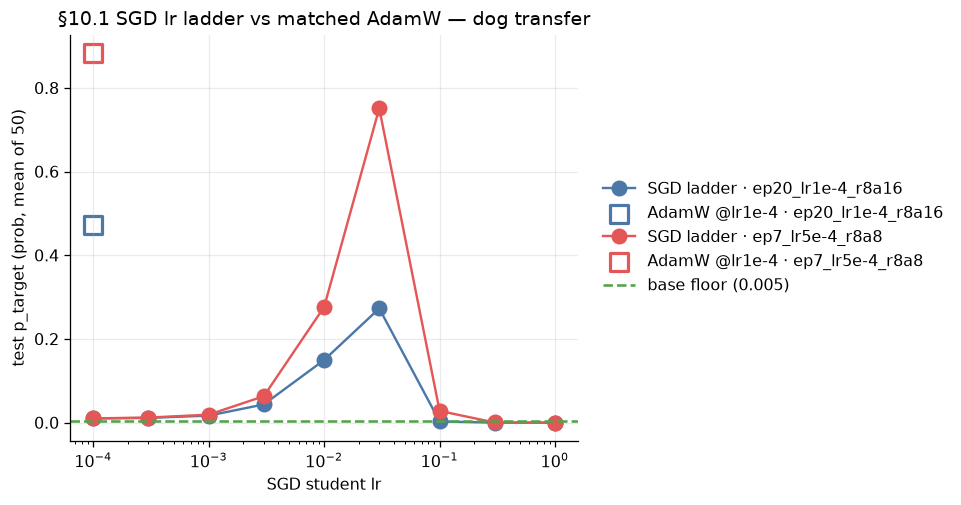

In [2]:
# §10.1 — ladder scan. lr parsed from the SGD leaf name ep10_lr{X}_r8a32_sgd.
LADDER_T10 = ["ep20_lr1e-4_r8a16", "ep7_lr5e-4_r8a8"]
_lr_re = re.compile(r"^ep10_lr([0-9.e+-]+)_r8a32_sgd$")

lad = []
_pairs31 = [(t, p) for t in LADDER_T10
            for p in sorted((STUD10 / "sgd" / TDIR10 / f"{t}_tseed1" / DATASET10).glob("ep10_lr*_r8a32_sgd"))]
for (t, p), doc in zip(_pairs31, _cell_docs10([p for _, p in _pairs31])):
    lad.append(dict(teacher=t, lr=float(_lr_re.match(p.name).group(1)),
                    p_target=_test_prob(doc, p)))
lad = pd.DataFrame(lad).sort_values(["teacher", "lr"]).reset_index(drop=True)
assert len(lad) == 18, len(lad)

print("row = one SGD student (ftseed1) at one lr; p_target = test/prob mean over 50 prompts")
display(lad.pivot(index="lr", columns="teacher", values="p_target").round(4))

fig, ax = plt.subplots(figsize=(8.5, 4.5))
colors = {"ep20_lr1e-4_r8a16": "#4c78a8", "ep7_lr5e-4_r8a8": "#e45756"}
for t, g in lad.groupby("teacher"):
    ax.plot(g.lr, g.p_target, "-o", ms=9, color=colors[t], label=f"SGD ladder · {t}")
    ax.scatter([1e-4], [tbl10.set_index("teacher").adamw[t]], marker="s", s=130,
               facecolor="none", edgecolor=colors[t], lw=2, label=f"AdamW @lr1e-4 · {t}")
ax.axhline(BASE_RATE10, ls="--", color="#54a24b", lw=1.6, label=f"base floor ({BASE_RATE10:.3f})")
ax.set_xscale("log")
ax.set_xlabel("SGD student lr")
ax.set_ylabel("test p_target (prob, mean of 50)")
ax.set_title("§10.1 SGD lr ladder vs matched AdamW — dog transfer")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=10)
fig.tight_layout(); plt.show()


### 10.2 Pile integrity of the SGD students — KL(base‖student) and ΔCE on pp1

All 21 SGD students (top-5 screen + ladder), probed with `scripts.pile_probe_final` on the pp1
pool (32 held-out Pile docs, ≤512 tok, seed 0); records at `{run_dir}/eval/pile_probe.json`.
Integrity reference: the population-derived collapse cut **KL > 7.9 nats** (KL modes ~1 vs ~15,
`docs/results/collapse_law.md`) — derived on AdamW populations, drawn here as a reference line,
not a calibrated SGD label.


row = one SGD student (ftseed1); KL/ΔCE in nats, position-pooled on pp1; base CE = 2.7082; integrity cut (reference) = KL > 7.9


,teacher,student_leaf,lr,kl,delta_ce
0,ep10_lr1e-4_r64a64,ep10_lr1e-4_r8a32_sgd,0.0001,0.0886,0.0823
1,ep20_lr1e-4_r16a32,ep10_lr1e-4_r8a32_sgd,0.0001,0.0890,0.0829
2,ep20_lr1e-4_r8a16,ep10_lr1e-4_r8a32_sgd,0.0001,0.0759,0.0724
3,ep20_lr1e-4_r8a16,ep10_lr3e-4_r8a32_sgd,0.0003,0.0805,0.0747
4,ep20_lr1e-4_r8a16,ep10_lr1e-3_r8a32_sgd,0.0010,0.1058,0.0946
5,ep20_lr1e-4_r8a16,ep10_lr3e-3_r8a32_sgd,0.0030,0.1759,0.1601
6,ep20_lr1e-4_r8a16,ep10_lr1e-2_r8a32_sgd,0.0100,0.4058,0.3970
7,ep20_lr1e-4_r8a16,ep10_lr3e-2_r8a32_sgd,0.0300,0.7351,0.7480
8,ep20_lr1e-4_r8a16,ep10_lr1e-1_r8a32_sgd,0.1000,6.7207,6.8751
9,ep20_lr1e-4_r8a16,ep10_lr3e-1_r8a32_sgd,0.3000,12.8322,13.0642


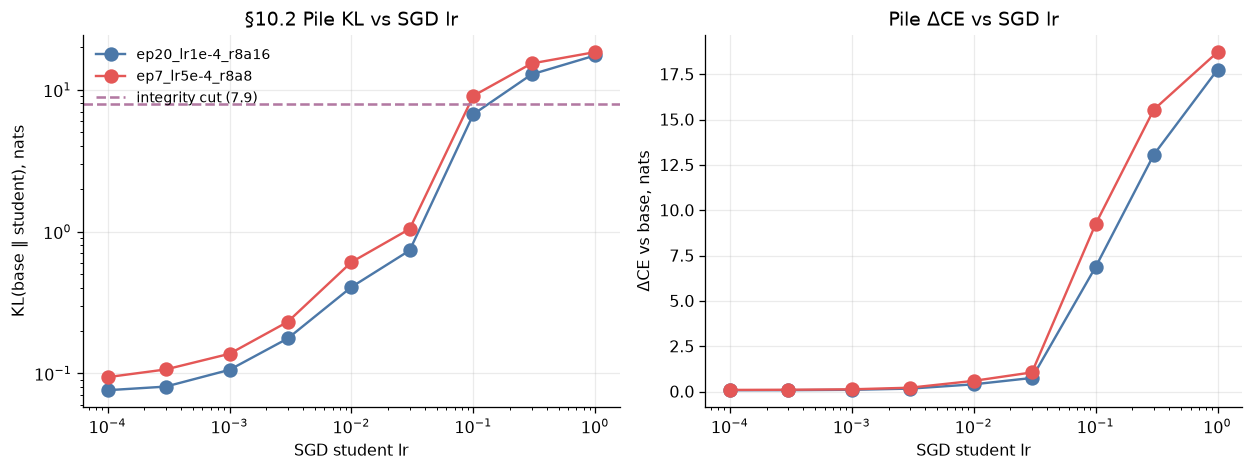

screen students @lr1e-4 — KL range: 0.0759–0.0974 · ΔCE range: +0.0724–+0.0936


In [3]:
# §10.2 — read every SGD pile_probe.json; join transfer where the run is a ladder cell.
from subliminal_learning.analysis import labels
from subliminal_learning.analysis.probe_cache import load_probe_cache

# OPERATIVE integrity cut: the per-receiver anchored cut (Δ_cross) of §10's receiver base,
# pythia-160m — the point where the student's absolute Pile CE reaches the unigram entropy.
KL_CUT10 = labels.anchored_cut(OUT10, "pythia-160m")
KL_CUT10_CMP = 7.9  # comparison only: the population-derived (AdamW) declared-era cut

_probe_paths33 = sorted((STUD10 / "sgd" / TDIR10).glob(f"*_tseed1/{DATASET10}/*/ftseed1/eval/pile_probe.json"))
_rels33 = [str(p.parents[1].relative_to(OUT10)) for p in _probe_paths33]   # the ftseed1 run dirs
_probe33 = load_probe_cache(OUT10, _rels33).set_index("run_path")
# The cache maps a diverged adapter (nonfinite adapter, or a null KL) to kl/delta_ce = +inf and
# nonfinite=True, so the assertion below still rejects exactly what the raw per-file read flagged.
CE_BASE10 = read_json(_probe_paths33[0])["ce_base"]   # single read: base CE is not a cached column

pk = []
for p, rel in zip(_probe_paths33, _rels33):
    rec = _probe33.loc[rel]
    leaf = p.parents[2].name
    pk.append(dict(teacher=p.parents[4].name.removesuffix("_tseed1"),
                   student_leaf=leaf,
                   lr=float(re.search(r"_lr([0-9.e+-]+)_", leaf).group(1)),
                   kl=float(rec.kl), delta_ce=float(rec.delta_ce),
                   ce_base=CE_BASE10, nonfinite=bool(rec.nonfinite)))
pk = pd.DataFrame(pk).sort_values(["teacher", "lr"]).reset_index(drop=True)
assert len(pk) == 21 and not pk.nonfinite.any(), (len(pk), int(pk.nonfinite.sum()))

print(f"row = one SGD student (ftseed1); KL/ΔCE in nats, position-pooled on pp1; "
      f"base CE = {pk.ce_base.iloc[0]:.4f}; anchored integrity cut = KL > {KL_CUT10:.2f} "
      f"(comparison: population/AdamW cut {KL_CUT10_CMP})")
display(pk.drop(columns=["ce_base", "nonfinite"]).round(4))

fig, axs = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True)
for t, g in pk[pk.teacher.isin(LADDER_T10)].groupby("teacher"):
    for ax, col in zip(axs, ["kl", "delta_ce"]):
        ax.plot(g.lr, g[col], "-o", ms=8, color=colors[t], label=t)
axs[0].axhline(KL_CUT10, ls="--", color="#b279a2", lw=1.6, label=f"anchored integrity cut ({KL_CUT10:.2f})")
axs[0].axhline(KL_CUT10_CMP, ls=":", color="#999999", lw=1.2, label=f"comparison cut ({KL_CUT10_CMP})")
axs[0].set_ylabel("KL(base ‖ student), nats"); axs[0].set_yscale("log")
axs[1].set_ylabel("ΔCE vs base, nats")
for ax in axs:
    ax.set_xscale("log"); ax.set_xlabel("SGD student lr")
axs[0].set_title("§10.2 Pile KL vs SGD lr"); axs[1].set_title("Pile ΔCE vs SGD lr")
axs[0].legend(loc="upper left", frameon=False, fontsize=9)
fig.tight_layout(); plt.show()

# The 5 screen students (lr 1e-4, one per top-5 teacher) in one line:
screen = pk[~pk.teacher.isin(LADDER_T10) | (pk.lr == 1e-4)].query("lr == 1e-4")
print("screen students @lr1e-4 — KL range:", f"{screen.kl.min():.4f}–{screen.kl.max():.4f}",
      "· ΔCE range:", f"{screen.delta_ce.min():+.4f}–{screen.delta_ce.max():+.4f}")


### Takeaways

- **§10.0 (screen):** at the AdamW-matched recipe (lr 1e-4) SGD sits at the base floor
  (p_target ≈ 0.010 vs AdamW 0.47–0.92) for all five top teachers.
- **§10.1 (ladder) — the screen's conclusion is superseded.** SGD transfer is a humped
  dose-response shifted ~300× to the right in lr: it rises monotonically to a peak at
  **lr 3e-2** (p_target 0.751 for `ep7_lr5e-4_r8a8`, 0.273 for `ep20_lr1e-4_r8a16` — i.e.
  ~85% / ~58% of the matched AdamW student), then crashes to ≤0.03 at lr ≥ 1e-1. The
  subliminal channel is not optimizer-dependent per se; the *effective dose scale* is.
  The earlier "optimizer choice alone kills transfer" reading was an lr-scale artifact.
- **§10.2 (integrity):** every student at lr ≤ 3e-2 is model-intact (KL 0.08–1.04 nats,
  far below the 7.9 reference cut; ΔCE tracks KL ≈ 1:1), so §10.0's dead transfer was an
  under-dosed intact model, not collapse. The transfer crash at lr ≥ 1e-1 coincides with
  integrity collapse (KL 6.7–9.1 at 1e-1, straddling the cut; 12.8–18.4 above it) — the
  same trait-rises-then-integrity-fails structure as the AdamW boundary, on SGD's coarser
  lr axis.
- Caveats: single `ftseed1` per cell; ladder covers 2 of the top-5 teachers; the KL cut is
  population-derived on AdamW arms and drawn here as a reference, not a calibrated SGD label.


## 11. Deck figure — same-init baseline across animals (headline_deck slide 5)

The slide-5 figure, rebuilt from this notebook's own frames (§7's `xwide` for the transfer values,
§9's `piv_s` for the rank agreement).

- **Row unit** = one teacher HP set (`{tag}_tseed1`) → its single same-init student at **ep10**.
- **Selection** = original `pythia-160m` base, plain `prefix` numbers, teacher/ft-seed 1, student
  seed 1, student recipe `lr1e-4/r8/α32`, restricted to the **intersection** of teacher configs
  computed for *all five* animals, so every animal is scored on an identical teacher menu.
- **Aggregation** = left panel shows the raw per-teacher held-out `test` p(target) distribution
  (box + jittered points, one point = one teacher); the red rule is that animal's own
  untrained-base prior. Right panel = median(test) ÷ that prior, one bar per animal.
- Priors come from `transfer_factors.load_priors` (`test_prior`, the same 50 held-out prompts;
  `behav_prior` is the documented fallback where the held-out base eval was never run).


shared teacher configs across all five animals @ ep10: 84


/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/pandas/core/algorithms.py:1715: UserWarning: short_model: 'pythia-160m@step100000' is not a pythia-160m-family name; passing it through unchanged. 160m-keyed joins will silently drop these rows — extend the label mapping before analyzing non-160m runs.
  return lib.map_infer(values, mapper)
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/pandas/core/algorithms.py:1715: UserWarning: short_model: 'pythia-160m@step125000' is not a pythia-160m-family name; passing it through unchanged. 160m-keyed joins will silently drop these rows — extend the label mapping before analyzing non-160m runs.
  return lib.map_infer(values, mapper)
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/pandas/core/algorithms.py:1715: UserWarning: short_model: 'pythia-160m@step25000' is not a pythia-160m-family name; passing it through unchanged. 160m-keyed joins will silently dr

prior fallback to behav_prior (no held-out base eval on the original base): ['rabbit']


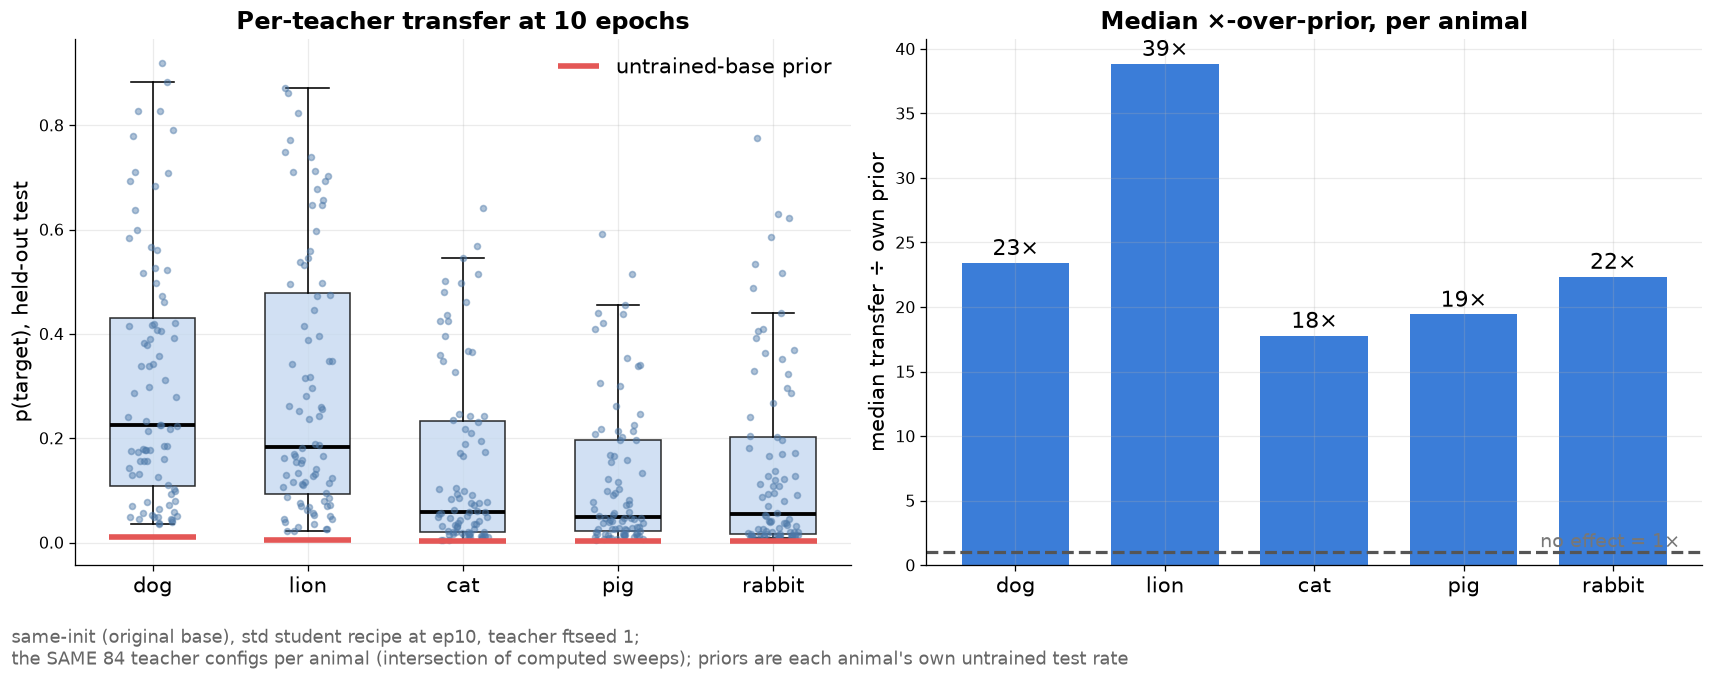

animal,n teachers,median test,prior,median ×-over-prior,Spearman vs dog (§9)
dog,84,0.226,0.0096,23.4,1.00
lion,84,0.184,0.0047,38.9,0.92
cat,84,0.059,0.0033,17.8,0.91
pig,84,0.049,0.0025,19.4,0.92
rabbit,84,0.054,0.0024,22.4,0.93


In [15]:
# §11 — the headline_deck slide-5 figure, rebuilt from §7's `xwide` (transfer) and §9's `piv_s` (ranking).
# Matched footing: original pythia-160m base, plain prefix numbers, tseed1/ftseed1, student seed 1,
# student recipe lr1e-4/r8/a32, student dose ep10, and the INTERSECTION of teacher configs present for
# all five animals -- so each animal's box aggregates over the identical teacher menu.
from subliminal_learning.analysis import transfer_factors as tf

DECK_ORDER, DECK_EP = ["dog", "lion", "cat", "pig", "rabbit"], 10
d11 = xwide[xwide.student_epochs.eq(DECK_EP) & xwide.animal.isin(DECK_ORDER)].dropna(subset=["student_test"])
SHARED11 = sorted(set.intersection(*[set(d11.loc[d11.animal.eq(a), "teacher_tag"]) for a in DECK_ORDER]))
d11 = d11[d11.teacher_tag.isin(SHARED11)]
assert SHARED11 and not d11.duplicated(["animal", "teacher_tag"]).any()
print(f"shared teacher configs across all five animals @ ep{DECK_EP}: {len(SHARED11)}")

# Each animal's own untrained-base prior on the ORIGINAL base: held-out `test` prompts where measured,
# else the favorite-set behavioural prior (rabbit has no held-out base eval on this base).
_pri = tf.load_priors(OUT9).query("base_label == 'original'").set_index("animal")
PRIOR11, _fallback = {}, []
for a in DECK_ORDER:
    v = _pri.at[a, "test_prior"]
    if not np.isfinite(v):
        v = _pri.at[a, "behav_prior"]; _fallback.append(a)
    PRIOR11[a] = float(v)
if _fallback:
    print("prior fallback to behav_prior (no held-out base eval on the original base):", _fallback)

vals = {a: d11.loc[d11.animal.eq(a), "student_test"].values for a in DECK_ORDER}
mult = {a: float(np.median(vals[a])) / PRIOR11[a] for a in DECK_ORDER}

fig, axs = plt.subplots(1, 2, figsize=(15, 5.4))
# (A) per-teacher spread of held-out test p(target), with each animal's untrained-base prior.
x = np.arange(1, len(DECK_ORDER) + 1)
bp = axs[0].boxplot([vals[a] for a in DECK_ORDER], positions=x, widths=.55, patch_artist=True,
                    showfliers=False, boxprops={"facecolor": "#c6d9f0", "alpha": .8},
                    medianprops={"color": "black", "lw": 2.4})
for xi, a in zip(x, DECK_ORDER):
    jit = aplots.jitter(len(vals[a]), .16, seed=0)
    axs[0].scatter(xi + jit, vals[a], s=14, alpha=.45, color="#4c78a8", zorder=3)
    axs[0].hlines(PRIOR11[a], xi - .28, xi + .28, color="#e45756", lw=3.5, zorder=4,
                  label="untrained-base prior" if a == DECK_ORDER[0] else None)
axs[0].set_xticks(x); axs[0].set_xticklabels(DECK_ORDER, fontsize=13)
axs[0].set_ylabel("p(target), held-out test", fontsize=13)
axs[0].set_title(f"Per-teacher transfer at {DECK_EP} epochs", fontsize=15, fontweight="bold")
axs[0].legend(fontsize=13, frameon=False, loc="upper right")
# (B) median x-over-prior per animal.
axs[1].bar(x, [mult[a] for a in DECK_ORDER], color="#3b7dd8", width=.72)
for xi, a in zip(x, DECK_ORDER):
    axs[1].text(xi, mult[a] + .6, f"{mult[a]:.0f}×", ha="center", fontsize=14)
axs[1].axhline(1, ls="--", color="#555555", lw=2)
axs[1].text(x[-1] + .45, 1.4, "no effect = 1×", ha="right", color="#777777", fontsize=12)
axs[1].set_xticks(x); axs[1].set_xticklabels(DECK_ORDER, fontsize=13)
axs[1].set_ylabel("median transfer ÷ own prior", fontsize=13)
axs[1].set_title("Median ×-over-prior, per animal", fontsize=15, fontweight="bold")
fig.text(.01, -.02,
         f"same-init (original base), std student recipe at ep{DECK_EP}, teacher ftseed 1;\n"
         f"the SAME {len(SHARED11)} teacher configs per animal (intersection of computed sweeps); "
         "priors are each animal's own untrained test rate",
         fontsize=11, color="#666666", va="top")
plt.tight_layout(); plt.show()

# Spearman of each animal's teacher ranking against dog's (§9's max-over-doses scores, all shared teachers).
def _rho_vs_dog(a):
    if a == "dog":
        return 1.0
    common = piv_s[["dog", a]].dropna()
    return float(common["dog"].corr(common[a], method="spearman"))

_rho = {a: _rho_vs_dog(a) for a in DECK_ORDER}
tbl11 = pd.DataFrame([{"animal": a, "n teachers": len(vals[a]), "median test": np.median(vals[a]),
                       "prior": PRIOR11[a], "median ×-over-prior": mult[a],
                       "Spearman vs dog (§9)": _rho[a]} for a in DECK_ORDER])
display(tbl11.style.hide(axis="index")
        .format({"median test": "{:.3f}", "prior": "{:.4f}", "median ×-over-prior": "{:.1f}",
                 "Spearman vs dog (§9)": "{:.2f}"})
        .set_caption(f"Row unit = one animal. `n teachers` = the shared teacher menu ({len(SHARED11)} configs, "
                     f"identical across animals) at student ep{DECK_EP}; `median test` = median over those "
                     "teachers of held-out test p(target); `prior` = that animal's untrained-base rate; "
                     "Spearman is §9's teacher-score rank correlation against dog over shared teachers."))


## 12. Standard-recipe dose series across animals — transfer and Pile CE (+ trait-free control) ⭐

One figure row on the **standard student recipe** (lr 1e-4, r8/α32, student-seed 1), same-init
original `pythia-160m`, plain prefix numbers, teacher-seed 1 — the §1 boxplot format extended to
every animal we have, with all animals on **one axis per panel** (colour = animal, boxes dodged
around each student-dose tick): **box = distribution over teacher-HP configs at one student
dose; every teacher is a jittered dot.** Left panel: held-out `test` trait transfer, **log y**.
Right panel: absolute Pile cross-entropy (`ce_student`, probe pool pp1) for the *same runs*.
Controls: the **trait-free teacher** (students distilled from raw-base-generated numbers — the
`base` lineage) and the `rng` control. At ep1–ep10 one canonical control run per source is a
marker (at the animal's box on the left, tick centre on the right). At **ep20** the controls are
**null boxes**: 10 fresh trait-free pools per source (draws 1–10), one student each — on the left
a grey box pair (base hatched, rng plain) just right of each animal's box, scored on that animal;
on the right one base and one rng box at the tick centre. Dotted lines are the untuned base:
per-animal p(target) on the left (animal colour), one Pile CE line on the right.

In [3]:
# §12 data — held-out trait transfer vs student dose, standard recipe, every animal.
# Row unit: one same-init teacher config (teacher-HP cell, plain prefix numbers, teacher-seed 1)
# distilled into original pythia-160m at lr1e-4 r8/a32, student-seed 1. Controls at the same
# recipe: canonical base-numbers (trait-free) and rng-numbers runs, plus at ep20 the 10-draw
# replicate pools (dataset ..._n100k_draw{N}) used as null boxes. The figure itself is drawn in
# the next cell together with the Pile-CE panel.
S12_LR, S12_RANK, S12_ALPHA = 1e-4, 8, 32
S12_DS = {"cat": "ex10-20_prefix_n40k"}
S12_NULL_EP = 20
s12 = treatments_all[treatments_all.same_init.eq(True) & treatments_all.model.eq("pythia-160m")
      & treatments_all.teacher_seed.eq(1) & treatments_all.student_seeds.map(lambda s: s == (1,))
      & treatments_all.student_lr.eq(S12_LR) & treatments_all.student_rank.eq(S12_RANK)
      & treatments_all.student_alpha.eq(S12_ALPHA)].copy()
s12 = s12[s12.dataset.eq(s12.animal.map(S12_DS).fillna("ex10-20_prefix_n100k"))]
S12_META = ["animal", "dataset", "teacher_tag", "student_epochs", "student_seeds"]
s12w = (s12.drop_duplicates("config_id").set_index("config_id")[S12_META]
        .join(s12.pivot(index="config_id", columns="set", values="p").add_prefix("student_"))
        .join(s12.pivot(index="config_id", columns="set", values="base_p").add_prefix("untuned_"))
        .reset_index())
S12_ANIMALS = sorted(s12w.animal.unique())
S12_EPS = sorted(s12w.student_epochs.unique())
ANIMAL_COLOR = {a: plt.cm.tab10.colors[i] for i, a in enumerate(S12_ANIMALS)}
print("standard-recipe same-init slice — configs per animal × student dose:")
display(pd.crosstab(s12w.animal, s12w.student_epochs))

# Controls at the standard recipe, split into canonical runs (markers, ep < 20) and draw replicates (ep20 nulls).
_c12all = controls_all[controls_all.model.eq("pythia-160m")
      & controls_all.student_lr.eq(S12_LR) & controls_all.student_rank.eq(S12_RANK)
      & controls_all.student_alpha.eq(S12_ALPHA) & controls_all.set.eq("test")].copy()
_is_draw = _c12all.dataset.str.fullmatch(r"ex10-20_prefix_n100k_draw\d+")
c12 = _c12all[~_is_draw & _c12all.dataset.eq("ex10-20_prefix_n100k") & _c12all.student_epochs.ne(S12_NULL_EP)]
d12 = _c12all[_is_draw & _c12all.student_epochs.eq(S12_NULL_EP) & _c12all.student_seeds.map(lambda s: s == (1,))].copy()
d12["draw"] = d12.dataset.str.extract(r"_draw(\d+)$")[0].astype(int)
print("canonical control rows (test set) by source × dose (markers):")
display(pd.crosstab(c12.source, c12.student_epochs) if len(c12) else "none found")
print(f"ep{S12_NULL_EP} draw-replicate students by source × scored animal (expect 10 each):")
display(pd.crosstab(d12.source, d12.animal) if len(d12) else "none found")

CTRL_STYLE = {"base": ("D", "#e45756", "trait-free (base numbers)"), "rng": ("^", "#72b7b2", "rng numbers")}
NULL_STYLE = {"base": {"facecolor": ".75", "hatch": "////"}, "rng": {"facecolor": ".92", "hatch": None}}
def s12_dodged(ax, values_by_animal, ylabel, title, ctrl_points=None, hline_by_animal=None, null_values=None):
    """One axis, all animals: boxes dodged around each student-dose tick (colour = animal, dots = teacher configs).

    values_by_animal: {animal: Series indexed by student_epochs}. ctrl_points: {source: DataFrame with
    student_epochs, value and (if animal-scored) animal}; a marker is drawn only where the animal has a
    treatment box at that dose (left) or at the tick centre (animal-agnostic). null_values: {source: values}
    drawn as grey null boxes at the S12_NULL_EP tick — {source: {animal: array}} places a base/rng pair just
    right of each animal's box, {source: array} places one pair at the tick centre.
    hline_by_animal: dotted untuned-base level per animal (animal colour); pass a single-key dict
    {None: level} for one grey line. Returns a {label: handle} dict for a shared legend.
    """
    nA = len(S12_ANIMALS); w = .8 / nA
    handles = {}
    for j, a in enumerate(S12_ANIMALS):
        sub = values_by_animal[a].dropna(); col = ANIMAL_COLOR[a]
        off = (j - (nA - 1) / 2) * w
        groups = [(S12_EPS.index(ep) + off, sub.loc[[ep]].values) for ep in sorted(sub.index.unique())]
        if groups:
            bp = ax.boxplot([v for _, v in groups], positions=[x for x, _ in groups], widths=w * .85,
                            patch_artist=True, showfliers=False, manage_ticks=False,
                            boxprops={"facecolor": col, "alpha": .3}, medianprops={"color": "black"})
            for x, v in groups:
                ax.scatter(x + np.linspace(-w * .3, w * .3, len(v)), v, s=12, alpha=.45, color=col)
            handles[a] = plt.matplotlib.patches.Patch(facecolor=col, alpha=.4, edgecolor="black")
        if hline_by_animal and a in hline_by_animal and not np.isnan(hline_by_animal[a]):
            ax.axhline(hline_by_animal[a], color=col, ls=":", lw=1.1)
    if hline_by_animal and None in hline_by_animal:
        ax.axhline(hline_by_animal[None], color=".35", ls=":", lw=1.3)
    for src, cc in (ctrl_points or {}).items():
        m, col, lab = CTRL_STYLE[src]
        cs = cc[cc.student_epochs.isin(S12_EPS)]
        if "animal" in cs:   # animal-scored: draw at this animal's box position, only where that box exists
            cs = cs[cs.animal.isin(S12_ANIMALS)]
            _has = {(a, ep) for a in S12_ANIMALS for ep in values_by_animal[a].dropna().index.unique()}
            cs = cs[[(a, e) in _has for a, e in zip(cs.animal, cs.student_epochs)]]   # no floating markers
            xs = [S12_EPS.index(e) + (S12_ANIMALS.index(a) - (nA - 1) / 2) * w for e, a in zip(cs.student_epochs, cs.animal)]
        else:                # animal-agnostic (Pile CE): tick centre
            xs = [S12_EPS.index(e) for e in cs.student_epochs]
        if len(cs):
            handles[f"{lab}, canonical run"] = ax.scatter(xs, cs.value, marker=m, s=90, color=col, edgecolor="black", lw=.5, zorder=5)
    if null_values and S12_NULL_EP in S12_EPS:
        x0 = S12_EPS.index(S12_NULL_EP)
        for k, (src, vals) in enumerate(null_values.items()):
            m, col, lab = CTRL_STYLE[src]
            if isinstance(vals, dict):   # per animal: thin pair to the right of the animal's box
                bw = w * .38
                slots = [(x0 + (S12_ANIMALS.index(a) - (nA - 1) / 2) * w + w * .45 + (k + .5) * bw, np.asarray(v))
                         for a, v in vals.items() if a in S12_ANIMALS and len(v)]
            else:                        # tick centre pair
                bw = w * 1.4
                slots = [(x0 + (k - .5) * bw * 1.1, np.asarray(vals))] if len(vals) else []
            if not slots: continue
            ax.boxplot([v for _, v in slots], positions=[x for x, _ in slots], widths=bw * .9, patch_artist=True,
                       showfliers=False, manage_ticks=False, zorder=4,
                       boxprops={"facecolor": NULL_STYLE[src]["facecolor"], "hatch": NULL_STYLE[src]["hatch"],
                                 "edgecolor": ".25"}, medianprops={"color": "black"})
            for x, v in slots:
                ax.scatter(x + np.linspace(-bw * .3, bw * .3, len(v)), v, s=6, color=".2", marker=m, alpha=.6, zorder=6)
            handles[f"{lab}: ep{S12_NULL_EP} null, 10 pool draws"] = plt.matplotlib.patches.Patch(
                facecolor=NULL_STYLE[src]["facecolor"], hatch=NULL_STYLE[src]["hatch"], edgecolor=".25")
    ax.set(title=title, xlabel="student epochs", ylabel=ylabel, xticks=range(len(S12_EPS)), xticklabels=S12_EPS)
    return handles

_vals12 = {a: s12w[s12w.animal.eq(a)].set_index("student_epochs").student_test for a in S12_ANIMALS}
_ctrl12 = {src: c12[c12.source.eq(src)].groupby(["animal", "student_epochs"]).p.mean().rename("value").reset_index()
           for src in c12.source.unique()} if len(c12) else {}
_null12 = {src: {a: g.p.values for a, g in d12[d12.source.eq(src)].groupby("animal")} for src in ("base", "rng")}
_untuned12 = {a: s12w[s12w.animal.eq(a)].untuned_test.dropna().median() for a in S12_ANIMALS}
print("median ep20 null p(target) by source × animal:")
display(d12.pivot_table(index="source", columns="animal", values="p", aggfunc="median").round(4) if len(d12) else "none")

standard-recipe same-init slice — configs per animal × student dose:


student_epochs,1,2,5,10,20
animal,,,,,
cat,84,84,84,84,0
dog,102,102,102,102,102
lion,96,96,96,96,0
pig,96,96,96,96,0
rabbit,92,92,92,92,0


control rows (test set) by source × dose:


student_epochs,1,2,5,10,20
source,,,,,
base,7,7,7,7,5
rng,7,7,7,7,5


pile_probe cache: 2004 rows of 66522 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)
probe rows: 2004/2004 runs (0 diverged=+inf, 0 treatment runs not probed yet)


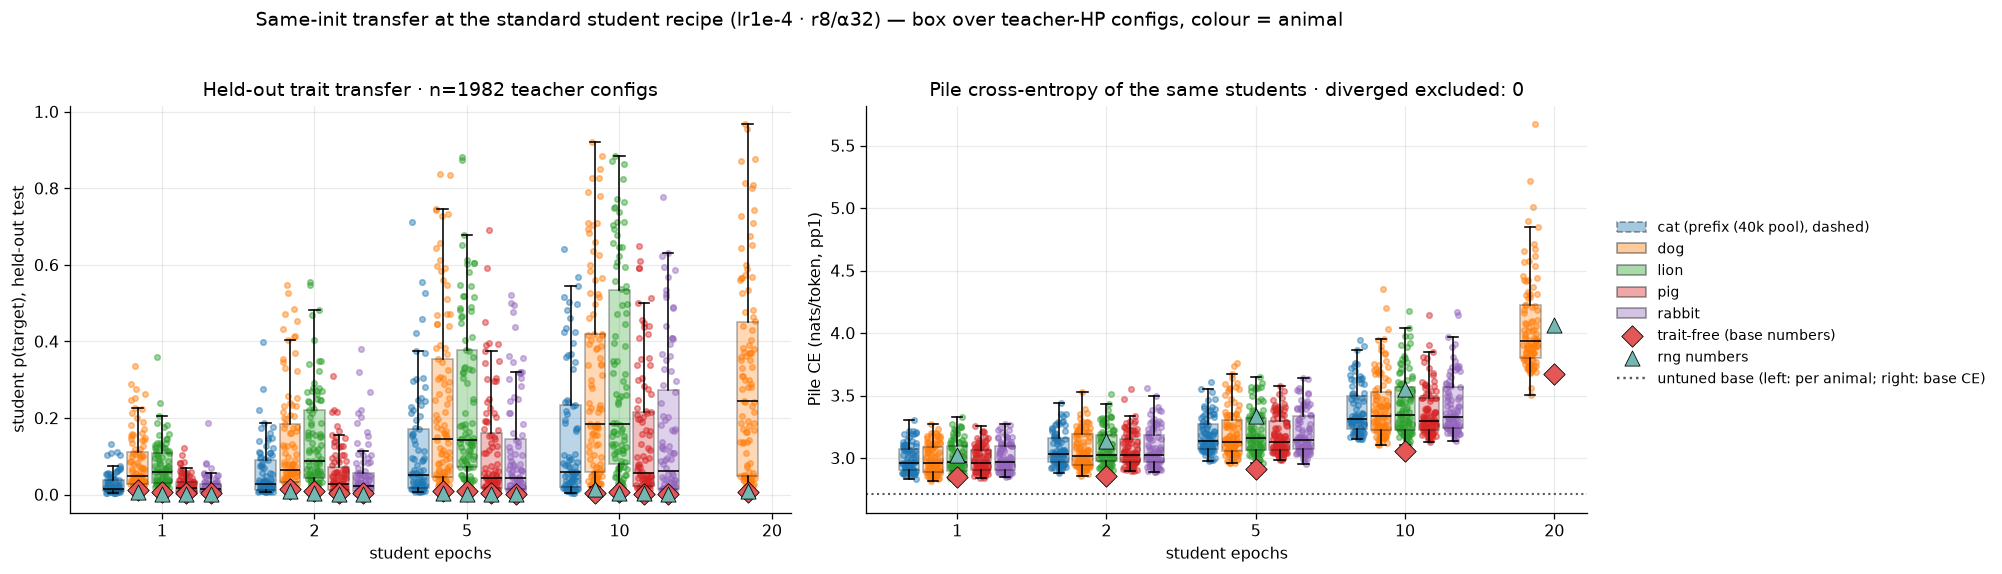

In [4]:
# §12 figure — left: held-out transfer vs student dose (log y); right: Pile cross-entropy (absolute
# ce_student, probe pool pp1) of the SAME runs. y_right = ce_student from {run}/eval/pile_probe.json
# via the probe cache; diverged adapters (+inf) are counted in the title, not plotted; dotted line =
# untuned base CE (median ce_base from the same records; ≈2.71 on pp1 for pythia-160m). Probe campaign:
# run_logs/queue_angela sameinit-std-pileprobe. ep20 controls = draw-replicate null boxes.
from pathlib import Path as _P
from matplotlib.lines import Line2D
from subliminal_learning.analysis.probe_cache import load_probe_cache

s12w["run_path"] = [f"{_P(c).relative_to(OUTPUT_ROOT)}/ftseed{s[0]}" for c, s in zip(s12w.config_id, s12w.student_seeds)]
_ctrl_runs = {src: sorted(str(p.relative_to(OUTPUT_ROOT))
              for p in (OUTPUT_ROOT/"students"/"controls"/src/"pythia-160m").glob("**/ep*_lr1e-4_r8a32/ftseed*")
              if (p/"train_manifest.json").is_file()) for src in ("base", "rng")}
pp = load_probe_cache(OUTPUT_ROOT, list(s12w.run_path) + sum(_ctrl_runs.values(), []))
pp_fin = pp[np.isfinite(pp.kl)]
s12w2 = s12w.merge(pp_fin[["run_path", "ce_student", "ce_base"]], on="run_path", how="left")
n_div = int((~np.isfinite(pp.kl)).sum())
print(f"probe rows: {len(pp)}/{len(s12w)+sum(map(len,_ctrl_runs.values()))} runs "
      f"({n_div} diverged=+inf, {int(s12w2.ce_student.isna().sum())} treatment runs not probed yet)")

_ce12 = {a: s12w2[s12w2.animal.eq(a)].set_index("student_epochs").ce_student for a in S12_ANIMALS}
def _ctrl_ce(src):
    sub = pp_fin[pp_fin.run_path.isin(_ctrl_runs[src])].copy()
    if not len(sub): return pd.DataFrame(columns=["dataset", "student_epochs", "value"])
    sub["student_epochs"] = sub.run_path.str.extract(r"/ep(\d+)_lr1e-4_r8a32/")[0].astype(int)
    sub["dataset"] = sub.run_path.str.extract(r"/(ex10-20_[^/]+|intro-[^/]+)/")[0]
    return sub.rename(columns={"ce_student": "value"})[["dataset", "student_epochs", "value"]]
_ctrlce_all = {src: _ctrl_ce(src) for src in ("base", "rng")}
_ctrlce12 = {src: d[d.dataset.eq("ex10-20_prefix_n100k") & d.student_epochs.ne(S12_NULL_EP)]
             .groupby("student_epochs").value.mean().reset_index() for src, d in _ctrlce_all.items()}
_ctrlce12 = {src: d for src, d in _ctrlce12.items() if len(d)}
_nullce12 = {src: d[d.dataset.str.fullmatch(r"ex10-20_prefix_n100k_draw\d+") & d.student_epochs.eq(S12_NULL_EP)].value.values
             for src, d in _ctrlce_all.items()}
print("ep20 draw-null Pile CE:", {src: f"n={len(v)} median={np.median(v):.4f}" if len(v) else "n=0" for src, v in _nullce12.items()})
_base_ce12 = float(s12w2.ce_base.dropna().median())

P_FLOOR12 = 1e-6   # log axis: clip any zero p(target) to this floor
_vals12_log = {a: v.clip(lower=P_FLOOR12) for a, v in _vals12.items()}
_ctrl12_log = {s: d.assign(value=d.value.clip(lower=P_FLOOR12)) for s, d in _ctrl12.items()}
_null12_log = {s: {a: np.clip(v, P_FLOOR12, None) for a, v in d.items()} for s, d in _null12.items()}

fig, (axL, axR) = plt.subplots(1, 2, figsize=(15, 5))
hL = s12_dodged(axL, _vals12_log, "student p(target), held-out test (log)",
                f"Held-out trait transfer · n={int(s12w.student_test.notna().sum())} teacher configs",
                ctrl_points=_ctrl12_log, hline_by_animal=_untuned12, null_values=_null12_log)
axL.set_yscale("log")
hR = s12_dodged(axR, _ce12, "Pile CE (nats/token, pp1)",
                f"Pile cross-entropy of the same students · diverged excluded: {n_div}",
                ctrl_points=_ctrlce12, hline_by_animal={None: _base_ce12}, null_values=_nullce12)
handles = {**hL, **hR}
handles["untuned base (left: per animal; right: base CE)"] = Line2D([], [], color=".35", ls=":")
fig.legend(handles.values(), handles.keys(), loc="center left", bbox_to_anchor=(1.0, .5), fontsize=9, frameon=False)
fig.suptitle("Same-init transfer at the standard student recipe (lr1e-4 · r8/α32) — box over teacher-HP configs, "
             "colour = animal; grey = ep20 control nulls", y=1.03, fontsize=12)
plt.tight_layout()
_fig_dir = ROOT / "notebooks" / "figures"; _fig_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(_fig_dir / "same_init_std_recipe_transfer_ce_with_draw_nulls.png", dpi=150, bbox_inches="tight")
plt.show()